In [3]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, mean_absolute_error, mean_squared_error, mean_squared_log_error, r2_score
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

In [5]:
df = pd.read_csv('/Users/auperry/Desktop/stretch assignment /cleaned_dummy_sales_data.csv')

In [28]:
df.head()

,Sales,Price,Promotion,Discount_Percentage,Quarter,year,month,day,week_of_year,month_sin,month_cos,Product_Category_0,Product_Category_1,Region_0,Region_1
0,3967.0,381.0,0.0,0.0,1.0,2022,3,31,13,1.0,6.123234e-17,1.0,0.0,0.0,1.0
46,3348.0,321.0,1.0,0.1,1.0,2022,3,31,13,1.0,6.123234e-17,0.0,0.0,1.0,0.0
70,3202.0,757.0,0.0,0.0,1.0,2022,3,31,13,1.0,6.123234e-17,0.0,1.0,0.0,1.0
34,1138.0,459.0,1.0,0.1,1.0,2022,3,31,13,1.0,6.123234e-17,0.0,0.0,0.0,1.0
82,2007.0,827.0,1.0,0.1,1.0,2022,3,31,13,1.0,6.123234e-17,0.0,1.0,1.0,0.0


In [44]:
df['Date'] = pd.to_datetime(df['Date'])

In [ ]:
df['year'] = df['Date'].dt.year
df['month'] = df['Date'].dt.month
df['day'] = df['Date'].dt.day
df['week_of_year'] = df['Date'].dt.isocalendar().week.astype(int)


# transform month into sine and cosine
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)
#df = df[(df['year'] > 2022) | (df['year'] < 2021)]

df = df.sort_values(by=['Date'])

In [ ]:
df['Sales_Lag1'] = df['Sales'].shift(1) # Sales from the previous day
df['Sales_Lag7'] = df['Sales'].shift(7) # Sales from 7 days ago (last week)
df['Sales_Lag30'] = df['Sales'].shift(30) # Sales from 30 days ago (last month)

# Rolling Mean Sales: Average sales over a recent period
# This helps capture trends. We shift by 1 to prevent "data leakage"
# (meaning the model doesn't "see" the sales it's trying to predict)
df['Sales_RollingMean7'] = df['Sales'].rolling(window=7).mean().shift(1) # Average sales over the last 7 days
df['Sales_RollingMean30'] = df['Sales'].rolling(window=30).mean().shift(1)

In [46]:
df = df.drop(columns = ['Date'])

In [ ]:
df = df.dropna(subset=['Sales'])

In [ ]:
from sklearn.impute import SimpleImputer, KNNImputer
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
imputer = KNNImputer(n_neighbors=5)
df[numerical_cols] = imputer.fit_transform(df[numerical_cols])

categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

In [ ]:
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
# encode categorical variables
encoder = OneHotEncoder(sparse_output=False, drop='first')  # Ensure dense output
for col in categorical_cols:
    # label encoding for binary categories
    if df[col].nunique() == 2:
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col])
    # one hot encoding for multiple categories
    elif df[col].nunique() > 2:
        encoded_cols = pd.DataFrame(
            encoder.fit_transform(df[[col]]),
            columns=[f"{col}_{i}" for i in range(encoder.fit_transform(df[[col]]).shape[1])],
            index=df.index
        )
        # drop the original column and concatenate encoded columns
        df = pd.concat([df.drop(columns=[col]), encoded_cols], axis=1)

In [ ]:
df_X = df.drop(columns = ['Sales'])
df_y = df['Sales']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(df_X, df_y, test_size = 0.2, shuffle = False, random_state = 42)

In [ ]:
model_RF = RandomForestRegressor(random_state = 42)
param_grid = {'n_estimators': [10, 20, 50, 100, 200, 500, 1000, 1500]}

# grid search with cv
grid_search = GridSearchCV(model_RF, param_grid, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Best n_estimators:", grid_search.best_params_['n_estimators'])
print("Best cross-validated MSE (negative):", grid_search.best_score_)
best_mse = -grid_search.best_score_
print("Best cross-validated MSE (positive):", best_mse)

Best n_estimators: 100
Best cross-validated MSE (negative): -960886.7470732352
Best cross-validated MSE (positive): 960886.7470732352


In [ ]:
model_RF_final = RandomForestRegressor(n_estimators=100, random_state=42)
model_RF_final.fit(X_train, y_train)

y_pred = model_RF_final.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
rrmse = rmse / np.mean(y_test)
r2 = r2_score(y_test, y_pred)
n = X_train.shape[0]
p = X_train.shape[1]
adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("Root Relative Mean Squared Error (RMSE):", rrmse)
print("R² Score:", r2)
print("Adjusted R-squared:", adjusted_r2)

Mean Absolute Error (MAE): 959.4168181818181
Mean Squared Error (MSE): 1244966.7481772727
Root Mean Squared Error (RMSE): 1115.780779623521
Root Relative Mean Squared Error (RMSE): 0.29532570353008897
R² Score: 0.2450792400280416
Adjusted R-squared: 0.09190691191778921


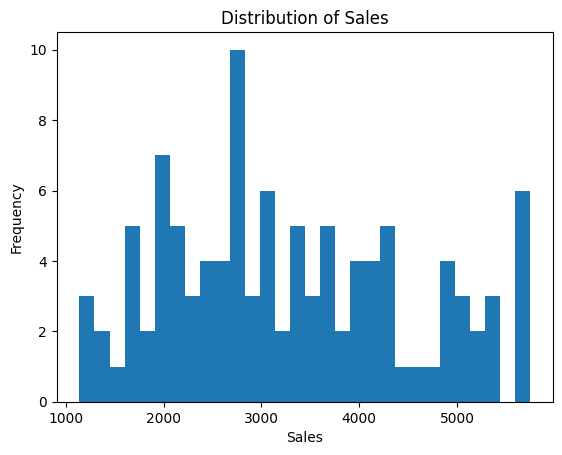

In [30]:
plt.hist(df_y, bins=30)
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.title("Distribution of Sales")
plt.show()

In [65]:
import pandas as pd
import numpy as np
from datetime import timedelta
import itertools

def generate_large_dummy_sales_data_with_lifecycle(
    start_date='2022-01-01',
    end_date='2024-12-31', # 3 full years of data
    product_lifecycle_map={
        'Meraki MR46': 'Early Growth',
        'Catalyst 9300': 'Growth',
        'Catalyst 2960-X/XR': 'Decline'
    },
    regions=['North America', 'EMEA', 'APAC']
):
    """
    Generates a large dummy sales dataset with multiple products, regions,
    and sales patterns influenced by product lifecycle phases.

    Args:
        start_date (str): Start date for the data generation.
        end_date (str): End date for the data generation.
        product_lifecycle_map (dict): Maps product names to their lifecycle phases.
        regions (list): List of geographical regions.

    Returns:
        pd.DataFrame: A DataFrame containing the generated sales data.
    """

    dates = pd.date_range(start=start_date, end=end_date, freq='D')
    
    # Define parameters for each lifecycle phase
    phase_parameters = {
        'Early Growth': {
            'base_sales_mult': 0.5,     # Starts lower
            'daily_trend': 1.5,         # Very steep growth per day
            'noise_mult': 1.5,          # More volatile sales
            'seasonality_impact': 0.8,  # Seasonality might be less dominant over rapid growth
            'promotion_impact': 1.5,    # Promotions have a larger effect
            'marketing_range': (100, 500)
        },
        'Growth': {
            'base_sales_mult': 1.0,
            'daily_trend': 0.5,         # Steady growth per day
            'noise_mult': 1.0,
            'seasonality_impact': 1.0,
            'promotion_impact': 1.0,
            'marketing_range': (50, 300)
        },
        'Decline': {
            'base_sales_mult': 1.2,     # Starts higher but declines
            'daily_trend': -0.8,        # Significant decline per day
            'noise_mult': 0.8,          # Less volatile sales
            'seasonality_impact': 1.2,  # Seasonality might be more apparent as overall sales drop
            'promotion_impact': 0.5,    # Promotions have less effect
            'marketing_range': (20, 150)
        }
    }

    # Base sales for each product (before phase multipliers)
    product_base_sales = {
        'Meraki MR46': 1000,
        'Catalyst 9300': 2500,
        'Catalyst 2960-X/XR': 3000
    }

    all_combinations = []
    for date in dates:
        for product_category, phase in product_lifecycle_map.items():
            for region in regions:
                all_combinations.append([date, product_category, region, phase])

    df = pd.DataFrame(all_combinations, columns=['Date', 'Product_Category', 'Region', 'Lifecycle_Phase'])

    # --- Generate Sales Data ---
    df['Sales'] = 0.0 # Initialize sales column

    # Calculate time index for trend
    df['Time_Index'] = (df['Date'] - df['Date'].min()).dt.days

    # Add Day of Year and Day of Week for seasonality
    df['Day_of_Year'] = df['Date'].dt.dayofyear
    df['Day_of_Week'] = df['Date'].dt.dayofweek # Monday=0, Sunday=6

    # Generate Promotion status
    df['Promotion'] = np.random.choice([0, 1], size=len(df), p=[0.8, 0.2])

    # Apply phase-specific sales logic
    for phase, params in phase_parameters.items():
        phase_df = df[df['Lifecycle_Phase'] == phase].copy()

        # Base sales for this product/phase
        base_sales_val = phase_df['Product_Category'].map(product_base_sales) * params['base_sales_mult']

        # Trend component
        trend_component = phase_df['Time_Index'] * params['daily_trend']

        # Yearly Seasonality
        yearly_seasonality = np.sin(phase_df['Day_of_Year'] * (2 * np.pi / 365)) * 500 * params['seasonality_impact']

        # Weekly Seasonality (lower sales on weekends)
        weekly_seasonality = phase_df['Day_of_Week'].isin([5, 6]) * 300 # Weekend sales reduction

        # Promotion impact
        promotion_impact = phase_df['Promotion'] * 200 * params['promotion_impact']

        # Random noise
        noise = np.random.normal(0, 100 * params['noise_mult'], len(phase_df))

        # Combine components
        calculated_sales = base_sales_val + trend_component + yearly_seasonality - weekly_seasonality + promotion_impact + noise

        # Update sales in the main DataFrame
        df.loc[df['Lifecycle_Phase'] == phase, 'Sales'] = calculated_sales

    # Ensure sales are not negative
    df['Sales'] = df['Sales'].clip(lower=0)

    # --- Generate Other Features ---
    # Price: Varies by product, with some random noise
    product_base_prices = {
        'Meraki MR46': 300,
        'Catalyst 9300': 1200,
        'Catalyst 2960-X/XR': 500
    }
    df['Price'] = df['Product_Category'].map(product_base_prices) + np.random.uniform(-50, 50, len(df))
    df['Price'] = df['Price'].clip(lower=100)

    # Marketing Spend: Varies by phase and sales volume
    df['Marketing_Spend'] = 0.0 # Initialize
    for phase, params in phase_parameters.items():
        df.loc[df['Lifecycle_Phase'] == phase, 'Marketing_Spend'] = np.random.uniform(
            params['marketing_range'][0], params['marketing_range'][1],
            len(df[df['Lifecycle_Phase'] == phase])
        ) + (df.loc[df['Lifecycle_Phase'] == phase, 'Sales'] / 50) # Scale with sales
    df['Marketing_Spend'] = df['Marketing_Spend'].clip(lower=20)


    # Add Region-specific adjustments (arbitrary, applied to final sales)
    region_multipliers = {
        'North America': 1.2,
        'EMEA': 1.0,
        'APAC': 0.8
    }
    df['Sales'] = df['Sales'] * df['Region'].map(region_multipliers)


    # Clean up temporary columns
    df = df.drop(columns=['Time_Index', 'Day_of_Year', 'Day_of_Week', 'Lifecycle_Phase'])

    # Reorder columns for clarity
    df = df[['Date', 'Product_Category', 'Region', 'Price', 'Marketing_Spend', 'Promotion', 'Sales']]

    return df

# --- Generate the data ---
new_dummy_data_lifecycle = generate_large_dummy_sales_data_with_lifecycle()

# --- Save the data to a new CSV file ---
output_file_path_lifecycle = '/Users/auperry/Desktop/stretch assignment /larger_dummy_sales_data_lifecycle.csv'
new_dummy_data_lifecycle.to_csv(output_file_path_lifecycle, index=False)

print(f"\nSuccessfully generated and saved a new dummy dataset to: {output_file_path_lifecycle}")
print(f"Total rows in new dataset: {len(new_dummy_data_lifecycle)}")
print("\nHead of the new dataset:")
print(new_dummy_data_lifecycle.head())
print("\nInfo of the new dataset:")
new_dummy_data_lifecycle.info()


Successfully generated and saved a new dummy dataset to: /Users/auperry/Desktop/stretch assignment /larger_dummy_sales_data_lifecycle.csv
Total rows in new dataset: 9864

Head of the new dataset:
        Date Product_Category         Region        Price  Marketing_Spend  \
0 2022-01-01      Meraki MR46  North America   259.579804       455.453866   
1 2022-01-01      Meraki MR46           EMEA   318.231247       302.346920   
2 2022-01-01      Meraki MR46           APAC   330.720474       431.663740   
3 2022-01-01    Catalyst 9300  North America  1232.568647       160.926795   
4 2022-01-01    Catalyst 9300           EMEA  1201.745908        99.996134   

   Promotion        Sales  
0          0   429.380546  
1          1   602.584231  
2          0   210.745390  
3          0  2715.993810  
4          0  2448.352831  

Info of the new dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9864 entries, 0 to 9863
Data columns (total 7 columns):
 #   Column            Non-Null Co

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt # Keep this for potential future plotting
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import KNNImputer
from lightgbm import LGBMRegressor # Make sure you have lightgbm installed: pip install lightgbm

# --- 1. Data Loading and Initial Date Conversion ---
# <<<<< YOU NEED TO EDIT HERE: Update this path to your new, larger dataset CSV >>>>>
df = pd.read_csv('/Users/auperry/Desktop/stretch assignment /larger_dummy_sales_data_lifecycle.csv')

print("--- Data Loading and Initial Inspection ---")
print("Original Data Head:")
print(df.head())
print("\nOriginal Data Info (before processing):")
df.info()
print(f"\nShape after loading CSV: {df.shape}") # DEBUGGING PRINT 1

# Convert 'Date' column to datetime objects FIRST
df['Date'] = pd.to_datetime(df['Date'])

# --- 2. Feature Engineering ---
# Create time-based features from the Date column
df['year'] = df['Date'].dt.year
df['month'] = df['Date'].dt.month
df['day'] = df['Date'].dt.day
df['day_of_week'] = df['Date'].dt.dayofweek # Monday=0, Sunday=6
df['week_of_year'] = df['Date'].dt.isocalendar().week # removed astype
df['quarter'] = df['Date'].dt.quarter
df['is_weekend'] = (df['Date'].dt.dayofweek >= 5).astype(int) # 1 if weekend, 0 otherwise

# Transform month into sine and cosine (for cyclical patterns)
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

# Sort by Date before creating lagged features (CRUCIAL for time series correctness)
df = df.sort_values(by=['Date']).reset_index(drop=True)

# Lagged Sales Features (powerful for sales forecasting, captures past patterns)
# These values represent sales from previous periods.
df['Sales_Lag1'] = df['Sales'].shift(1)
df['Sales_Lag7'] = df['Sales'].shift(7)
df['Sales_Lag30'] = df['Sales'].shift(30)
# <<<<< YOU NEED TO EDIT HERE: UNCOMMENT THESE LONGER LAGS FOR YOUR LARGER DATASET >>>>>
df['Sales_Lag90'] = df['Sales'].shift(90)
df['Sales_Lag180'] = df['Sales'].shift(180)
df['Sales_Lag365'] = df['Sales'].shift(365)

# Rolling Mean Sales (captures trends, shifted by 1 to avoid data leakage)
# These represent average sales over a recent window.
df['Sales_RollingMean7'] = df['Sales'].rolling(window=7).mean().shift(1)
df['Sales_RollingMean30'] = df['Sales'].rolling(window=30).mean().shift(1)
# <<<<< YOU NEED TO EDIT HERE: UNCOMMENT THESE LONGER ROLLING MEANS FOR YOUR LARGER DATASET >>>>>
df['Sales_RollingMean90'] = df['Sales'].rolling(window=90).mean().shift(1)
df['Sales_RollingMean365'] = df['Sales'].rolling(window=365).mean().shift(1)

# Now it's safe to drop the original 'Date' column
df = df.drop(columns = ['Date'])

print(f"\nShape after feature engineering (before dropping NaNs): {df.shape}") # DEBUGGING PRINT 2

# --- 3. Handle NaNs from Lagged Features and Target Variable ---
# IMPORTANT: Adjust the 'subset' list to ONLY include the lags you are actually creating!
print(f"\nShape before dropping NaNs from lags/target: {df.shape}")
df = df.dropna(subset=[
    'Sales_Lag1', 'Sales_Lag7', 'Sales_Lag30',
    # <<<<< YOU NEED TO EDIT HERE: UNCOMMENT THESE LONGER LAGS FOR YOUR LARGER DATASET >>>>>
    'Sales_Lag90', 'Sales_Lag180', 'Sales_Lag365',
    'Sales_RollingMean7', 'Sales_RollingMean30',
    # <<<<< YOU NEED TO EDIT HERE: UNCOMMENT THESE LONGER ROLLING MEANS FOR YOUR LARGER DATASET >>>>>
    'Sales_RollingMean90', 'Sales_RollingMean365',
    'Sales' # Ensure target variable is not NaN
])
print(f"Shape after dropping NaNs from lags/target: {df.shape}") # DEBUGGING PRINT 3

# --- 4. Separate Features (X) and Target (y) ---
df_X = df.drop(columns = ['Sales'])
df_y = df['Sales']

print(f"\nShape of df_X before train_test_split: {df_X.shape}") # DEBUGGING PRINT 4

# --- 5. Time Series Train/Test Split (CRUCIAL: Split before imputation/encoding) ---
X_train, X_test, y_train, y_test = train_test_split(df_X, df_y, test_size = 0.2, shuffle = False)

print(f"\nShape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")

# --- 6. Handle Missing Values (Imputation) AFTER SPLIT ---
numerical_cols_train = X_train.select_dtypes(include=['int64', 'float64']).columns
imputer = KNNImputer(n_neighbors=5)
if len(numerical_cols_train) > 0:
    X_train[numerical_cols_train] = imputer.fit_transform(X_train[numerical_cols_train])
    X_test[numerical_cols_train] = imputer.transform(X_test[numerical_cols_train])
    print("\nKNN Imputation applied to numerical columns (fitted on train, transformed train/test).")
else:
    print("\nNo numerical columns found for KNN Imputation.")

# --- 7. Categorical Feature Encoding AFTER SPLIT ---
categorical_cols_train = X_train.select_dtypes(include=['object']).columns
print(f"\nIdentified categorical columns for encoding: {list(categorical_cols_train)}")

for col in categorical_cols_train:
    if X_train[col].nunique() == 2:
        le = LabelEncoder()
        all_categories = pd.concat([X_train[col], X_test[col]]).unique()
        le.fit(all_categories)
        X_train[col] = le.transform(X_train[col])
        X_test[col] = le.transform(X_test[col])
        print(f"Label encoded column: {col}")
    elif X_train[col].nunique() > 2:
        ohe = OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore')
        ohe.fit(X_train[[col]])
        encoded_train_cols = pd.DataFrame(ohe.transform(X_train[[col]]),
                                          columns=ohe.get_feature_names_out([col]),
                                          index=X_train.index)
        encoded_test_cols = pd.DataFrame(ohe.transform(X_test[[col]]),
                                         columns=ohe.get_feature_names_out([col]),
                                         index=X_test.index)
        X_train = pd.concat([X_train.drop(columns=[col]), encoded_train_cols], axis=1)
        X_test = pd.concat([X_test.drop(columns=[col]), encoded_test_cols], axis=1)
        print(f"One-Hot encoded column: {col}")

missing_cols_in_test = set(X_train.columns) - set(X_test.columns)
for c in missing_cols_in_test:
    X_test[c] = 0
X_test = X_test[X_train.columns]

print("\n--- DataFrame Info after all preprocessing and feature engineering ---")
print("X_train info:")
X_train.info()
print("\nX_test info:")
X_test.info()
print("\nX_train head (after all preprocessing):")
print(X_train.head())

# --- 8. Hyperparameter Tuning with GridSearchCV (Random Forest) ---
model_RF = RandomForestRegressor(random_state = 42)

# Parameters for GridSearchCV. You can expand these if you have time.
param_grid_rf = {
    'n_estimators': [100, 200, 500], # More estimators for larger data
    'max_features': ['sqrt', 'log2', 0.8], # More options for feature selection
    'max_depth': [10, 20, None] # Deeper trees for more complex data
}

print("\n--- Starting GridSearchCV for Random Forest Hyperparameter Tuning ---")
grid_search_rf = GridSearchCV(model_RF, param_grid_rf, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, verbose=2)
grid_search_rf.fit(X_train, y_train)

print("\nRandom Forest Best parameters:", grid_search_rf.best_params_)
print("Random Forest Best cross-validated MSE (positive):", -grid_search_rf.best_score_)

best_RF_model = grid_search_rf.best_estimator_

# --- 9. Final Model Evaluation (Random Forest) ---
print("\n--- Evaluating Final Random Forest Model ---")
y_pred_rf = best_RF_model.predict(X_test)

mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)

n_rf = X_train.shape[0]
p_rf = X_train.shape[1]
adjusted_r2_rf = 1 - (1 - r2_rf) * (n_rf - 1) / (n_rf - p_rf - 1) if (n_rf - p_rf - 1) > 0 else float('nan')
rrmse_rf = rmse_rf / np.mean(y_test) if np.mean(y_test) != 0 else float('inf')

print("Random Forest MAE:", mae_rf)
print("Random Forest MSE:", mse_rf)
print("Random Forest RMSE:", rmse_rf)
print("Random Forest RRMSE:", rrmse_rf)
print("Random Forest R² Score:", r2_rf)
print("Random Forest Adjusted R-squared:", adjusted_r2_rf)

feature_importances_rf = pd.Series(best_RF_model.feature_importances_, index=X_train.columns)
print("\nRandom Forest Top 15 Feature Importances:")
print(feature_importances_rf.nlargest(15))

# --- 10. Introducing LightGBM (Your Second Model) ---
model_LGBM = LGBMRegressor(random_state=42)

# Parameters for GridSearchCV. You can expand these if you have time.
param_grid_lgbm = {
    'n_estimators': [100, 200, 500],
    'learning_rate': [0.05, 0.1],
    'num_leaves': [31, 63, 127], # More leaves for larger data
    'max_depth': [-1, 10, 20] # -1 means no limit
}

print("\n--- Starting GridSearchCV for LightGBM Hyperparameter Tuning ---")
grid_search_lgbm = GridSearchCV(model_LGBM, param_grid_lgbm, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, verbose=2)
grid_search_lgbm.fit(X_train, y_train)

print("\nLightGBM Best parameters:", grid_search_lgbm.best_params_)
print("LightGBM Best cross-validated MSE (positive):", -grid_search_lgbm.best_score_)

best_LGBM_model = grid_search_lgbm.best_estimator_

# --- 11. Final Model Evaluation (LightGBM) ---
print("\n--- Evaluating Final LightGBM Model ---")
y_pred_lgbm = best_LGBM_model.predict(X_test)

mse_lgbm = mean_squared_error(y_test, y_pred_lgbm)
rmse_lgbm = np.sqrt(mse_lgbm)
r2_lgbm = r2_score(y_test, y_pred_lgbm)
mae_lgbm = mean_absolute_error(y_test, y_pred_lgbm)

n_lgbm = X_train.shape[0]
p_lgbm = X_train.shape[1]
adjusted_r2_lgbm = 1 - (1 - r2_lgbm) * (n_lgbm - 1) / (n_lgbm - p_lgbm - 1) if (n_lgbm - p_lgbm - 1) > 0 else float('nan')
rrmse_lgbm = rmse_lgbm / np.mean(y_test) if np.mean(y_test) != 0 else float('inf')

print("LightGBM MAE:", mae_lgbm)
print("LightGBM MSE:", mse_lgbm)
print("LightGBM RMSE:", rmse_lgbm)
print("LightGBM RRMSE:", rrmse_lgbm)
print("LightGBM R² Score:", r2_lgbm)
print("LightGBM Adjusted R-squared:", adjusted_r2_lgbm)

feature_importances_lgbm = pd.Series(best_LGBM_model.feature_importances_, index=X_train.columns)
print("\nLightGBM Top 15 Feature Importances:")
print(feature_importances_lgbm.nlargest(15))

# --- 12. Comparison ---
print("\n--- Model Comparison ---")
print(f"Random Forest R²: {r2_rf:.4f}")
print(f"LightGBM R²: {r2_lgbm:.4f}")
# Add your XGBoost R² here for comparison
# print(f"XGBoost R²: {your_xgboost_r2_score:.4f}")

--- Data Loading and Initial Inspection ---
Original Data Head:
         Date Product_Category         Region        Price  Marketing_Spend  \
0  2022-01-01      Meraki MR46  North America   259.579804       455.453866   
1  2022-01-01      Meraki MR46           EMEA   318.231247       302.346920   
2  2022-01-01      Meraki MR46           APAC   330.720474       431.663740   
3  2022-01-01    Catalyst 9300  North America  1232.568647       160.926795   
4  2022-01-01    Catalyst 9300           EMEA  1201.745908        99.996134   

   Promotion        Sales  
0          0   429.380546  
1          1   602.584231  
2          0   210.745390  
3          0  2715.993810  
4          0  2448.352831  

Original Data Info (before processing):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9864 entries, 0 to 9863
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              9864 non-null   object 
 1   

0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0

[CV] END ..max_depth=10, max_features=sqrt, n_estimators=100; total time=   1.4s
[CV] END ..max_depth=10, max_features=sqrt, n_estimators=100; total time=   1.4s
[CV] END ..max_depth=10, max_features=sqrt, n_estimators=100; total time=   1.4s
[CV] END ..max_depth=10, max_features=sqrt, n_estimators=100; total time=   1.4s
[CV] END ..max_depth=10, max_features=sqrt, n_estimators=100; total time=   1.5s
[CV] END ..max_depth=10, max_features=log2, n_estimators=100; total time=   1.2s
[CV] END ..max_depth=10, max_features=log2, n_estimators=100; total time=   1.2s
[CV] END ..max_depth=10, max_features=sqrt, n_estimators=200; total time=   2.8s
[CV] END ..max_depth=10, max_features=sqrt, n_estimators=200; total time=   2.8s
[CV] END ..max_depth=10, max_features=sqrt, n_estimators=200; total time=   2.9s
[CV] END ..max_depth=10, max_features=sqrt, n_estimators=200; total time=   3.0s
[CV] END ..max_depth=10, max_features=sqrt, n_estimators=200; total time=   3.0s
[CV] END ..max_depth=10, max

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
0.01s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.


[CV] END ..max_depth=20, max_features=log2, n_estimators=500; total time=   7.9s
[CV] END ..max_depth=20, max_features=log2, n_estimators=500; total time=   7.9s
[CV] END ...max_depth=20, max_features=0.8, n_estimators=100; total time=   6.0s


0.01s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.


... (7 outputs left out)

0.01s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006849 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3208
[LightGBM] [Info] Number of data points in the train set: 6079, number of used features: 26
[LightGB

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.07s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.


[CV] END learning_rate=0.05, max_depth=-1, n_estimators=100, num_leaves=63; total time=  15.5s
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.121498 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3208
[LightGBM] [Info] Number of data points in the train set: 6079, number of used features: 26
[LightGBM] [Info] Start training from score 2371.956001
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007563 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3208
[LightGBM] [Info] Number of data points in the train set: 6079, number of use

In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt # Keep this for potential future plotting
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import KNNImputer
from lightgbm import LGBMRegressor # Make sure you have lightgbm installed
import xgboost as xgb # <<<<< NEW: Import XGBoost >>>>>

# --- 1. Data Loading and Initial Date Conversion ---
# <<<<< YOU NEED TO EDIT HERE: Update this path to your new, larger dataset CSV >>>>>
df = pd.read_csv('/Users/auperry/Desktop/stretch assignment /larger_dummy_sales_data_lifecycle.csv')

print("--- Data Loading and Initial Inspection ---")
print("Original Data Head:")
print(df.head())
print("\nOriginal Data Info (before processing):")
df.info()
print(f"\nShape after loading CSV: {df.shape}") # DEBUGGING PRINT 1

# Convert 'Date' column to datetime objects FIRST
df['Date'] = pd.to_datetime(df['Date'])

# --- 2. Feature Engineering ---
# Create time-based features from the Date column
df['year'] = df['Date'].dt.year
df['month'] = df['Date'].dt.month
df['day'] = df['Date'].dt.day
df['day_of_week'] = df['Date'].dt.dayofweek # Monday=0, Sunday=6
df['week_of_year'] = df['Date'].dt.isocalendar().week.astype(int) # Ensure integer type
df['quarter'] = df['Date'].dt.quarter
df['is_weekend'] = (df['Date'].dt.dayofweek >= 5).astype(int) # 1 if weekend, 0 otherwise

# Transform month into sine and cosine (for cyclical patterns)
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

# Sort by Date before creating lagged features (CRUCIAL for time series correctness)
df = df.sort_values(by=['Date']).reset_index(drop=True)

# Lagged Sales Features (powerful for sales forecasting, captures past patterns)
# These values represent sales from previous periods.
df['Sales_Lag1'] = df['Sales'].shift(1)
df['Sales_Lag7'] = df['Sales'].shift(7)
df['Sales_Lag30'] = df['Sales'].shift(30)
# <<<<< YOU NEED TO EDIT HERE: UNCOMMENT THESE LONGER LAGS FOR YOUR LARGER DATASET >>>>>
df['Sales_Lag90'] = df['Sales'].shift(90)
df['Sales_Lag180'] = df['Sales'].shift(180)
df['Sales_Lag365'] = df['Sales'].shift(365)

# Rolling Mean Sales (captures trends, shifted by 1 to avoid data leakage)
# These represent average sales over a recent window.
df['Sales_RollingMean7'] = df['Sales'].rolling(window=7).mean().shift(1)
df['Sales_RollingMean30'] = df['Sales'].rolling(window=30).mean().shift(1)
# <<<<< YOU NEED TO EDIT HERE: UNCOMMENT THESE LONGER ROLLING MEANS FOR YOUR LARGER DATASET >>>>>
df['Sales_RollingMean90'] = df['Sales'].rolling(window=90).mean().shift(1)
df['Sales_RollingMean365'] = df['Sales'].rolling(window=365).mean().shift(1)

# Now it's safe to drop the original 'Date' column
df = df.drop(columns = ['Date'])

print(f"\nShape after feature engineering (before dropping NaNs): {df.shape}") # DEBUGGING PRINT 2

# --- 3. Handle NaNs from Lagged Features and Target Variable ---
# IMPORTANT: Adjust the 'subset' list to ONLY include the lags you are actually creating!
print(f"\nShape before dropping NaNs from lags/target: {df.shape}")
df = df.dropna(subset=[
    'Sales_Lag1', 'Sales_Lag7', 'Sales_Lag30',
    # <<<<< YOU NEED TO EDIT HERE: UNCOMMENT THESE LONGER LAGS FOR YOUR LARGER DATASET >>>>>
    'Sales_Lag90', 'Sales_Lag180', 'Sales_Lag365',
    'Sales_RollingMean7', 'Sales_RollingMean30',
    # <<<<< YOU NEED TO EDIT HERE: UNCOMMENT THESE LONGER ROLLING MEANS FOR YOUR LARGER DATASET >>>>>
    'Sales_RollingMean90', 'Sales_RollingMean365',
    'Sales' # Ensure target variable is not NaN
])
print(f"Shape after dropping NaNs from lags/target: {df.shape}") # DEBUGGING PRINT 3

# --- 4. Separate Features (X) and Target (y) ---
df_X = df.drop(columns = ['Sales'])
df_y = df['Sales']

print(f"\nShape of df_X before train_test_split: {df_X.shape}") # DEBUGGING PRINT 4

# --- 5. Time Series Train/Test Split (CRUCIAL: Split before imputation/encoding) ---
X_train, X_test, y_train, y_test = train_test_split(df_X, df_y, test_size = 0.2, shuffle = False)

print(f"\nShape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")

# --- 6. Handle Missing Values (Imputation) AFTER SPLIT ---
numerical_cols_train = X_train.select_dtypes(include=['int64', 'float64']).columns
imputer = KNNImputer(n_neighbors=5)
if len(numerical_cols_train) > 0:
    X_train[numerical_cols_train] = imputer.fit_transform(X_train[numerical_cols_train])
    X_test[numerical_cols_train] = imputer.transform(X_test[numerical_cols_train])
    print("\nKNN Imputation applied to numerical columns (fitted on train, transformed train/test).")
else:
    print("\nNo numerical columns found for KNN Imputation.")

# --- 7. Categorical Feature Encoding AFTER SPLIT ---
categorical_cols_train = X_train.select_dtypes(include=['object']).columns
print(f"\nIdentified categorical columns for encoding: {list(categorical_cols_train)}")

for col in categorical_cols_train:
    if X_train[col].nunique() == 2:
        le = LabelEncoder()
        all_categories = pd.concat([X_train[col], X_test[col]]).unique()
        le.fit(all_categories)
        X_train[col] = le.transform(X_train[col])
        X_test[col] = le.transform(X_test[col])
        print(f"Label encoded column: {col}")
    elif X_train[col].nunique() > 2:
        ohe = OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore')
        ohe.fit(X_train[[col]])
        encoded_train_cols = pd.DataFrame(ohe.transform(X_train[[col]]),
                                          columns=ohe.get_feature_names_out([col]),
                                          index=X_train.index)
        encoded_test_cols = pd.DataFrame(ohe.transform(X_test[[col]]),
                                         columns=ohe.get_feature_names_out([col]),
                                         index=X_test.index)
        X_train = pd.concat([X_train.drop(columns=[col]), encoded_train_cols], axis=1)
        X_test = pd.concat([X_test.drop(columns=[col]), encoded_test_cols], axis=1)
        print(f"One-Hot encoded column: {col}")

missing_cols_in_test = set(X_train.columns) - set(X_test.columns)
for c in missing_cols_in_test:
    X_test[c] = 0
X_test = X_test[X_train.columns]

print("\n--- DataFrame Info after all preprocessing and feature engineering ---")
print("X_train info:")
X_train.info()
print("\nX_test info:")
X_test.info()
print("\nX_train head (after all preprocessing):")
print(X_train.head())

# --- 8. Hyperparameter Tuning with GridSearchCV (Random Forest) ---
model_RF = RandomForestRegressor(random_state = 42)

param_grid_rf = {
    'n_estimators': [100, 200, 500],
    'max_features': ['sqrt', 'log2', 0.8],
    'max_depth': [10, 20, None]
}

print("\n--- Starting GridSearchCV for Random Forest Hyperparameter Tuning ---")
grid_search_rf = GridSearchCV(model_RF, param_grid_rf, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, verbose=2)
grid_search_rf.fit(X_train, y_train)

print("\nRandom Forest Best parameters:", grid_search_rf.best_params_)
print("Random Forest Best cross-validated MSE (positive):", -grid_search_rf.best_score_)

best_RF_model = grid_search_rf.best_estimator_

# --- 9. Final Model Evaluation (Random Forest) ---
print("\n--- Evaluating Final Random Forest Model ---")
y_pred_rf = best_RF_model.predict(X_test)

mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)

n_rf = X_train.shape[0]
p_rf = X_train.shape[1]
adjusted_r2_rf = 1 - (1 - r2_rf) * (n_rf - 1) / (n_rf - p_rf - 1) if (n_rf - p_rf - 1) > 0 else float('nan')
rrmse_rf = rmse_rf / np.mean(y_test) if np.mean(y_test) != 0 else float('inf')

print("Random Forest MAE:", mae_rf)
print("Random Forest MSE:", mse_rf)
print("Random Forest RMSE:", rmse_rf)
print("Random Forest RRMSE:", rrmse_rf)
print("Random Forest R² Score:", r2_rf)
print("Random Forest Adjusted R-squared:", adjusted_r2_rf)

feature_importances_rf = pd.Series(best_RF_model.feature_importances_, index=X_train.columns)
print("\nRandom Forest Top 15 Feature Importances:")
print(feature_importances_rf.nlargest(15))

# --- 10. Hyperparameter Tuning with GridSearchCV (LightGBM) ---
model_LGBM = LGBMRegressor(random_state=42)

param_grid_lgbm = {
    'n_estimators': [100, 200, 500],
    'learning_rate': [0.05, 0.1],
    'num_leaves': [31, 63, 127],
    'max_depth': [-1, 10, 20]
}

print("\n--- Starting GridSearchCV for LightGBM Hyperparameter Tuning ---")
grid_search_lgbm = GridSearchCV(model_LGBM, param_grid_lgbm, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, verbose=2)
grid_search_lgbm.fit(X_train, y_train)

print("\nLightGBM Best parameters:", grid_search_lgbm.best_params_)
print("LightGBM Best cross-validated MSE (positive):", -grid_search_lgbm.best_score_)

best_LGBM_model = grid_search_lgbm.best_estimator_

# --- 11. Final Model Evaluation (LightGBM) ---
print("\n--- Evaluating Final LightGBM Model ---")
y_pred_lgbm = best_LGBM_model.predict(X_test)

mse_lgbm = mean_squared_error(y_test, y_pred_lgbm)
rmse_lgbm = np.sqrt(mse_lgbm)
r2_lgbm = r2_score(y_test, y_pred_lgbm)
mae_lgbm = mean_absolute_error(y_test, y_pred_lgbm)

n_lgbm = X_train.shape[0]
p_lgbm = X_train.shape[1]
adjusted_r2_lgbm = 1 - (1 - r2_lgbm) * (n_lgbm - 1) / (n_lgbm - p_lgbm - 1) if (n_lgbm - p_lgbm - 1) > 0 else float('nan')
rrmse_lgbm = rmse_lgbm / np.mean(y_test) if np.mean(y_test) != 0 else float('inf')

print("LightGBM MAE:", mae_lgbm)
print("LightGBM MSE:", mse_lgbm)
print("LightGBM RMSE:", rmse_lgbm)
print("LightGBM RRMSE:", rrmse_lgbm)
print("LightGBM R² Score:", r2_lgbm)
print("LightGBM Adjusted R-squared:", adjusted_r2_lgbm)

feature_importances_lgbm = pd.Series(best_LGBM_model.feature_importances_, index=X_train.columns)
print("\nLightGBM Top 15 Feature Importances:")
print(feature_importances_lgbm.nlargest(15))


# --- 12. Hyperparameter Tuning with GridSearchCV (XGBoost) ---
# <<<<< NEW SECTION FOR XGBOOST >>>>>
model_XGB = xgb.XGBRegressor(objective='reg:squarederror', random_state=42) # objective for regression

param_grid_xgb = {
    'n_estimators': [100, 200, 500],
    'learning_rate': [0.05, 0.1],
    'max_depth': [6, 10, 15], # Common max_depth values for XGBoost
    'subsample': [0.8, 1.0], # Fraction of samples used for fitting the trees
    'colsample_bytree': [0.8, 1.0] # Fraction of features used for fitting the trees
}

print("\n--- Starting GridSearchCV for XGBoost Hyperparameter Tuning ---")
grid_search_xgb = GridSearchCV(model_XGB, param_grid_xgb, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, verbose=2)
grid_search_xgb.fit(X_train, y_train)

print("\nXGBoost Best parameters:", grid_search_xgb.best_params_)
print("XGBoost Best cross-validated MSE (positive):", -grid_search_xgb.best_score_)

best_XGB_model = grid_search_xgb.best_estimator_

# --- 13. Final Model Evaluation (XGBoost) ---
print("\n--- Evaluating Final XGBoost Model ---")
y_pred_xgb = best_XGB_model.predict(X_test)

mse_xgb = mean_squared_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mse_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)

n_xgb = X_train.shape[0]
p_xgb = X_train.shape[1]
adjusted_r2_xgb = 1 - (1 - r2_xgb) * (n_xgb - 1) / (n_xgb - p_xgb - 1) if (n_xgb - p_xgb - 1) > 0 else float('nan')
rrmse_xgb = rmse_xgb / np.mean(y_test) if np.mean(y_test) != 0 else float('inf')

print("XGBoost MAE:", mae_xgb)
print("XGBoost MSE:", mse_xgb)
print("XGBoost RMSE:", rmse_xgb)
print("XGBoost RRMSE:", rrmse_xgb)
print("XGBoost R² Score:", r2_xgb)
print("XGBoost Adjusted R-squared:", adjusted_r2_xgb)

feature_importances_xgb = pd.Series(best_XGB_model.feature_importances_, index=X_train.columns)
print("\nXGBoost Top 15 Feature Importances:")
print(feature_importances_xgb.nlargest(15))

# --- 14. Overall Model Comparison ---
print("\n--- Overall Model Comparison (R² Score) ---")
print(f"Random Forest R²: {r2_rf:.4f}")
print(f"LightGBM R²: {r2_lgbm:.4f}")
print(f"XGBoost R²: {r2_xgb:.4f}")

--- Data Loading and Initial Inspection ---
Original Data Head:
         Date Product_Category         Region        Price  Marketing_Spend  \
0  2022-01-01      Meraki MR46  North America   259.579804       455.453866   
1  2022-01-01      Meraki MR46           EMEA   318.231247       302.346920   
2  2022-01-01      Meraki MR46           APAC   330.720474       431.663740   
3  2022-01-01    Catalyst 9300  North America  1232.568647       160.926795   
4  2022-01-01    Catalyst 9300           EMEA  1201.745908        99.996134   

   Promotion        Sales  
0          0   429.380546  
1          1   602.584231  
2          0   210.745390  
3          0  2715.993810  
4          0  2448.352831  

Original Data Info (before processing):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9864 entries, 0 to 9863
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              9864 non-null   object 
 1   

0.01s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0

[CV] END ..max_depth=10, max_features=sqrt, n_estimators=100; total time=   1.4s
[CV] END ..max_depth=10, max_features=sqrt, n_estimators=100; total time=   1.4s
[CV] END ..max_depth=10, max_features=sqrt, n_estimators=100; total time=   1.4s
[CV] END ..max_depth=10, max_features=sqrt, n_estimators=100; total time=   1.4s
[CV] END ..max_depth=10, max_features=sqrt, n_estimators=100; total time=   1.4s
[CV] END ..max_depth=10, max_features=log2, n_estimators=100; total time=   1.3s
[CV] END ..max_depth=10, max_features=log2, n_estimators=100; total time=   1.4s
[CV] END ..max_depth=10, max_features=sqrt, n_estimators=200; total time=   2.9s
[CV] END ..max_depth=10, max_features=sqrt, n_estimators=200; total time=   2.9s
[CV] END ..max_depth=10, max_features=sqrt, n_estimators=200; total time=   2.9s
[CV] END ..max_depth=10, max_features=sqrt, n_estimators=200; total time=   3.0s
[CV] END ..max_depth=10, max_features=sqrt, n_estimators=200; total time=   3.0s
[CV] END ..max_depth=10, max

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.


[CV] END ...max_depth=20, max_features=0.8, n_estimators=100; total time=   5.9s
[CV] END ...max_depth=20, max_features=0.8, n_estimators=100; total time=   5.9s
[CV] END ...max_depth=20, max_features=0.8, n_estimators=100; total time=   6.0s
[CV] END max_depth=None, max_features=sqrt, n_estimators=100; total time=   1.9s
[CV] END max_depth=None, max_features=sqrt, n_estimators=100; total time=   1.9s
[CV] END max_depth=None, max_features=sqrt, n_estimators=100; total time=   1.8s
[CV] END max_depth=None, max_features=sqrt, n_estimators=100; total time=   1.9s
[CV] END max_depth=None, max_features=sqrt, n_estimators=100; total time=   1.9s
[CV] END ...max_depth=20, max_features=0.8, n_estimators=200; total time=  12.0s
[CV] END ...max_depth=20, max_features=0.8, n_estimators=200; total time=  12.0s
[CV] END ...max_depth=20, max_features=0.8, n_estimators=200; total time=  12.0s
[CV] END max_depth=None, max_features=sqrt, n_estimators=200; total time=   3.7s
[CV] END max_depth=None, max

0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.


... (21 outputs left out)

0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.


[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=15, n_estimators=100, subsample=1.0; total time=  10.0s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=15, n_estimators=200, subsample=0.8; total time=  17.8s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=15, n_estimators=200, subsample=0.8; total time=  18.4s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=15, n_estimators=200, subsample=0.8; total time=  18.7s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=15, n_estimators=200, subsample=0.8; total time=  18.8s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=15, n_estimators=200, subsample=0.8; total time=  18.7s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=15, n_estimators=200, subsample=1.0; total time=  22.8s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=15, n_estimators=200, subsample=1.0; total time=  21.6s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=15,

0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.


[CV] END colsample_bytree=1.0, learning_rate=0.1, max_depth=10, n_estimators=200, subsample=0.8; total time=   4.8s
[CV] END colsample_bytree=1.0, learning_rate=0.1, max_depth=10, n_estimators=200, subsample=0.8; total time=   5.0s
[CV] END colsample_bytree=1.0, learning_rate=0.1, max_depth=10, n_estimators=200, subsample=0.8; total time=   4.7s
[CV] END colsample_bytree=1.0, learning_rate=0.1, max_depth=10, n_estimators=200, subsample=0.8; total time=   4.8s
[CV] END colsample_bytree=1.0, learning_rate=0.1, max_depth=10, n_estimators=200, subsample=0.8; total time=   5.1s
[CV] END colsample_bytree=1.0, learning_rate=0.1, max_depth=10, n_estimators=200, subsample=1.0; total time=   5.1s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=15, n_estimators=500, subsample=1.0; total time=  45.6s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=15, n_estimators=500, subsample=1.0; total time=  41.8s
[CV] END colsample_bytree=1.0, learning_rate=0.1, max_depth=10, n_esti

--- Data Loading and Initial Inspection ---
Original Data Head:
         Date Product_Category         Region        Price  Marketing_Spend  \
0  2022-01-01      Meraki MR46  North America   259.579804       455.453866   
1  2022-01-01      Meraki MR46           EMEA   318.231247       302.346920   
2  2022-01-01      Meraki MR46           APAC   330.720474       431.663740   
3  2022-01-01    Catalyst 9300  North America  1232.568647       160.926795   
4  2022-01-01    Catalyst 9300           EMEA  1201.745908        99.996134   

   Promotion        Sales  
0          0   429.380546  
1          1   602.584231  
2          0   210.745390  
3          0  2715.993810  
4          0  2448.352831  

Original Data Info (before processing):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9864 entries, 0 to 9863
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              9864 non-null   object 
 1   

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[CV] END colsample_bytree=0.8, learning_rate=0.1, max_depth=6, n_estimators=100, subsample=0.8; total time=   0.2s
[CV] END colsample_bytree=0.8, learning_rate=0.1, max_depth=6, n_estimators=100, subsample=0.8; total time=   0.2s
[CV] END colsample_bytree=0.8, learning_rate=0.1, max_depth=6, n_estimators=100, subsample=0.8; total time=   0.2s
[CV] END colsample_bytree=0.8, learning_rate=0.1, max_depth=6, n_estimators=100, subsample=1.0; total time=   0.2s
[CV] END colsample_bytree=0.8, learning_rate=0.1, max_depth=6, n_estimators=100, subsample=1.0; total time=   0.2s
[CV] END colsample_bytree=0.8, learning_rate=0.1, max_depth=6, n_estimators=100, subsample=1.0; total time=   0.2s
[CV] END colsample_bytree=0.8, learning_rate=0.1, max_depth=6, n_estimators=100, subsample=1.0; total time=   0.2s
[CV] END colsample_bytree=0.8, learning_rate=0.1, max_depth=6, n_estimators=200, subsample=0.8; total time=   0.3s
[CV] END colsample_bytree=0.8, learning_rate=0.1, max_depth=6, n_estimators=200,

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KNNImputer was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KNNImputer was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KNNImputer was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KNNImputer was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/va

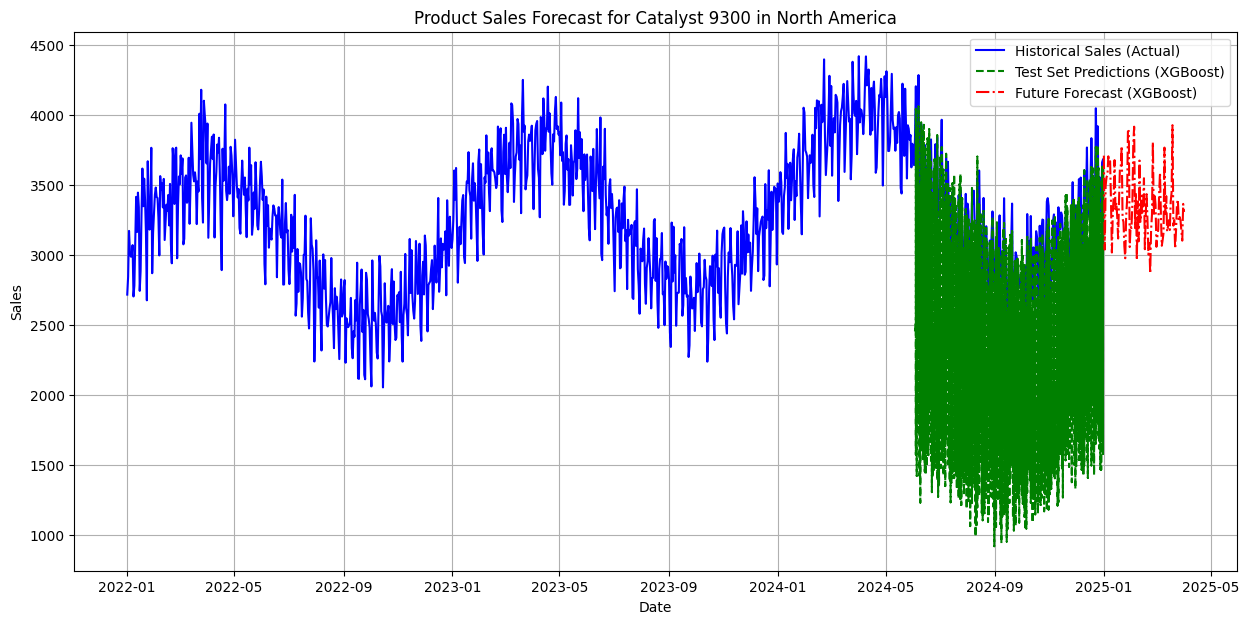


Forecast and Visualization complete!


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import KNNImputer
from lightgbm import LGBMRegressor
import xgboost as xgb

# --- 1. Data Loading and Initial Date Conversion ---
# IMPORTANT: Replace this path with the actual path to your new, larger dataset CSV
df_original_full = pd.read_csv('/Users/auperry/Desktop/stretch assignment /larger_dummy_sales_data_lifecycle.csv')
df = df_original_full.copy()

print("--- Data Loading and Initial Inspection ---")
print("Original Data Head:")
print(df.head())
print("\nOriginal Data Info (before processing):")
df.info()
print(f"\nShape after loading CSV: {df.shape}")

# Convert 'Date' column to datetime objects FIRST
df['Date'] = pd.to_datetime(df['Date'])

# --- Store original Date, Product_Category, Region for later use (plotting, future data generation) ---
df_identifiers = df[['Date', 'Product_Category', 'Region', 'Sales']].copy()

# --- 2. Feature Engineering ---
# Create time-based features from the Date column
df['year'] = df['Date'].dt.year
df['month'] = df['Date'].dt.month
df['day'] = df['Date'].dt.day
df['day_of_week'] = df['Date'].dt.dayofweek
# <<<<< EDITED HERE: Removed .astype(int) >>>>>
df['week_of_year'] = df['Date'].dt.isocalendar().week
df['quarter'] = df['Date'].dt.quarter
df['is_weekend'] = (df['Date'].dt.dayofweek >= 5).astype(int)

# Transform month into sine and cosine (for cyclical patterns)
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

# Sort by Date before creating lagged features (CRUCIAL for time series correctness)
df = df.sort_values(by=['Date', 'Product_Category', 'Region']).reset_index(drop=True)

# Lagged Sales Features (powerful for sales forecasting, captures past patterns)
df['Sales_Lag1'] = df['Sales'].shift(1)
df['Sales_Lag7'] = df['Sales'].shift(7)
df['Sales_Lag30'] = df['Sales'].shift(30)
# <<<<< UNCOMMENT THESE LONGER LAGS FOR YOUR LARGER DATASET >>>>>
df['Sales_Lag90'] = df['Sales'].shift(90)
df['Sales_Lag180'] = df['Sales'].shift(180)
df['Sales_Lag365'] = df['Sales'].shift(365)

# Rolling Mean Sales (captures trends, shifted by 1 to avoid data leakage)
df['Sales_RollingMean7'] = df['Sales'].rolling(window=7).mean().shift(1)
df['Sales_RollingMean30'] = df['Sales'].rolling(window=30).mean().shift(1)
# <<<<< UNCOMMENT THESE LONGER ROLLING MEANS FOR YOUR LARGER DATASET >>>>>
df['Sales_RollingMean90'] = df['Sales'].rolling(window=90).mean().shift(1)
df['Sales_RollingMean365'] = df['Sales'].rolling(window=365).mean().shift(1)

# Drop the original 'Date' column from the main df for modeling
df = df.drop(columns = ['Date'])

print(f"\nShape after feature engineering (before dropping NaNs): {df.shape}")

# --- 3. Handle NaNs from Lagged Features and Target Variable ---
print(f"\nShape before dropping NaNs from lags/target: {df.shape}")
df = df.dropna(subset=[
    'Sales_Lag1', 'Sales_Lag7', 'Sales_Lag30',
    # <<<<< UNCOMMENT THESE LONGER LAGS FOR YOUR LARGER DATASET >>>>>
    'Sales_Lag90', 'Sales_Lag180', 'Sales_Lag365',
    'Sales_RollingMean7', 'Sales_RollingMean30',
    # <<<<< UNCOMMENT THESE LONGER ROLLING MEANS FOR YOUR LARGER DATASET >>>>>
    'Sales_RollingMean90', 'Sales_RollingMean365',
    'Sales'
])
print(f"Shape after dropping NaNs from lags/target: {df.shape}")

# --- 4. Separate Features (X) and Target (y) ---
df_X = df.drop(columns = ['Sales'])
df_y = df['Sales']

print(f"\nShape of df_X before train_test_split: {df_X.shape}")

# --- 5. Time Series Train/Test Split (CRUCIAL: Split before imputation/encoding) ---
train_size = int(len(df_X) * 0.8)
train_indices = df_X.index[:train_size]
test_indices = df_X.index[train_size:]

X_train = df_X.loc[train_indices]
X_test = df_X.loc[test_indices]
y_train = df_y.loc[train_indices]
y_test = df_y.loc[test_indices]

# Get the dates for train and test sets for plotting
train_dates = df_identifiers.loc[train_indices, 'Date']
test_dates = df_identifiers.loc[test_indices, 'Date']

print(f"\nShape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")

# --- 6. Handle Missing Values (Imputation) AFTER SPLIT ---
numerical_cols_train = X_train.select_dtypes(include=['int64', 'float64']).columns
imputer = KNNImputer(n_neighbors=5)
if len(numerical_cols_train) > 0:
    X_train[numerical_cols_train] = imputer.fit_transform(X_train[numerical_cols_train])
    X_test[numerical_cols_train] = imputer.transform(X_test[numerical_cols_train])

# --- 7. Categorical Feature Encoding AFTER SPLIT ---
categorical_cols_train = X_train.select_dtypes(include=['object']).columns

label_encoders = {}
one_hot_encoders = {}

for col in categorical_cols_train:
    if X_train[col].nunique() == 2:
        le = LabelEncoder()
        all_categories = pd.concat([X_train[col], X_test[col]]).unique()
        le.fit(all_categories)
        X_train[col] = le.transform(X_train[col])
        X_test[col] = le.transform(X_test[col])
        label_encoders[col] = le
    elif X_train[col].nunique() > 2:
        ohe = OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore')
        ohe.fit(X_train[[col]])

        encoded_train_cols = pd.DataFrame(ohe.transform(X_train[[col]]),
                                          columns=ohe.get_feature_names_out([col]),
                                          index=X_train.index)
        encoded_test_cols = pd.DataFrame(ohe.transform(X_test[[col]]),
                                         columns=ohe.get_feature_names_out([col]),
                                         index=X_test.index)
        X_train = pd.concat([X_train.drop(columns=[col]), encoded_train_cols], axis=1)
        X_test = pd.concat([X_test.drop(columns=[col]), encoded_test_cols], axis=1)
        one_hot_encoders[col] = ohe

missing_cols_in_test = set(X_train.columns) - set(X_test.columns)
for c in missing_cols_in_test:
    X_test[c] = 0
X_test = X_test[X_train.columns]

print("\n--- DataFrame Info after all preprocessing and feature engineering ---")
print("X_train info:")
X_train.info()
print("\nX_test info:")
X_test.info()
print("\nX_train head (after all preprocessing):")
print(X_train.head())

# --- 8. Hyperparameter Tuning with GridSearchCV (Random Forest) ---
model_RF = RandomForestRegressor(random_state = 42)
param_grid_rf = {
    'n_estimators': [100, 200, 500],
    'max_features': ['sqrt', 'log2', 0.8],
    'max_depth': [10, 20, None]
}
print("\n--- Starting GridSearchCV for Random Forest Hyperparameter Tuning ---")
grid_search_rf = GridSearchCV(model_RF, param_grid_rf, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, verbose=0)
grid_search_rf.fit(X_train, y_train)
best_RF_model = grid_search_rf.best_estimator_
y_pred_rf = best_RF_model.predict(X_test)
r2_rf = r2_score(y_test, y_pred_rf)

# --- 9. Hyperparameter Tuning with GridSearchCV (LightGBM) ---
model_LGBM = LGBMRegressor(random_state=42)
param_grid_lgbm = {
    'n_estimators': [100, 200, 500],
    'learning_rate': [0.05, 0.1],
    'num_leaves': [31, 63, 127],
    'max_depth': [-1, 10, 20]
}
print("\n--- Starting GridSearchCV for LightGBM Hyperparameter Tuning ---")
grid_search_lgbm = GridSearchCV(model_LGBM, param_grid_lgbm, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, verbose=0)
grid_search_lgbm.fit(X_train, y_train)
best_LGBM_model = grid_search_lgbm.best_estimator_
y_pred_lgbm = best_LGBM_model.predict(X_test)
r2_lgbm = r2_score(y_test, y_pred_lgbm)

# --- 10. Hyperparameter Tuning with GridSearchCV (XGBoost) ---
model_XGB = xgb.XGBRegressor(objective='reg:squarederror', random_state=42)
param_grid_xgb = {
    'n_estimators': [100, 200, 500],
    'learning_rate': [0.05, 0.1],
    'max_depth': [6, 10, 15],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}
print("\n--- Starting GridSearchCV for XGBoost Hyperparameter Tuning ---")
grid_search_xgb = GridSearchCV(model_XGB, param_grid_xgb, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, verbose=2)
grid_search_xgb.fit(X_train, y_train)
best_XGB_model = grid_search_xgb.best_estimator_
y_pred_xgb = best_XGB_model.predict(X_test)
r2_xgb = r2_score(y_test, y_pred_xgb)

print("\n--- Overall Model Comparison (R² Score) ---")
print(f"Random Forest R²: {r2_rf:.4f}")
print(f"LightGBM R²: {r2_lgbm:.4f}")
print(f"XGBoost R²: {r2_xgb:.4f}")

# --- NEW SECTION: Forecasting and Visualization ---

print("\n--- Beginning Forecasting and Visualization ---")

# 1. Prepare data for plotting historical actuals and test predictions
historical_data_for_plot = df_identifiers.copy()

# 2. Define the forecasting horizon (e.g., next 3 months or 1 quarter)
forecast_start_date = historical_data_for_plot['Date'].max() + pd.Timedelta(days=1)
forecast_end_date = forecast_start_date + pd.Timedelta(days=90)

# Create a DataFrame for future dates
future_dates_range = pd.date_range(start=forecast_start_date, end=forecast_end_date, freq='D')

# Get unique product categories and regions from your original full data
unique_product_categories = df_original_full['Product_Category'].unique()
unique_regions = df_original_full['Region'].unique()

# Create all combinations of future dates, products, and regions
future_data_list = []
for date in future_dates_range:
    for product in unique_product_categories:
        for region in unique_regions:
            future_data_list.append({'Date': date, 'Product_Category': product, 'Region': region})

future_df = pd.DataFrame(future_data_list)

# --- 3. Feature Engineering for Future Dates ---
# Apply the same feature engineering steps as on the training data
future_df['year'] = future_df['Date'].dt.year
future_df['month'] = future_df['Date'].dt.month
future_df['day'] = future_df['Date'].dt.day
future_df['day_of_week'] = future_df['Date'].dt.dayofweek
# <<<<< EDITED HERE: Removed .astype(int) >>>>>
future_df['week_of_year'] = future_df['Date'].dt.isocalendar().week
future_df['quarter'] = future_df['Date'].dt.quarter
future_df['is_weekend'] = (future_df['Date'].dt.dayofweek >= 5).astype(int)
future_df['month_sin'] = np.sin(2 * np.pi * future_df['month'] / 12)
future_df['month_cos'] = np.cos(2 * np.pi * future_df['month'] / 12)

# For 'Price', 'Marketing_Spend', 'Promotion' in future_df:
# Use the mean of the training data.
for col in ['Price', 'Marketing_Spend', 'Promotion']:
    if col in X_train.columns:
        future_df[col] = X_train[col].mean()
    else:
        future_df[col] = 0

# --- Prepare full_data_for_lags for iterative forecasting ---
# This DataFrame will hold historical actuals and then be updated with predictions
# for calculating future lags.
full_data_for_lags = historical_data_for_plot.copy()
# Add a placeholder 'Sales' column to future_df for concatenation
future_df_for_lags_concat = future_df.copy()
future_df_for_lags_concat['Sales'] = np.nan
full_data_for_lags = pd.concat([full_data_for_lags, future_df_for_lags_concat], ignore_index=True)
full_data_for_lags['Date'] = pd.to_datetime(full_data_for_lags['Date'])
full_data_for_lags = full_data_for_lags.sort_values(by=['Date', 'Product_Category', 'Region']).reset_index(drop=True)

start_forecast_idx = len(historical_data_for_plot)

print(f"\nCalculated start_forecast_idx: {start_forecast_idx}")
print(f"Total rows in full_data_for_lags: {len(full_data_for_lags)}")
if start_forecast_idx < len(full_data_for_lags):
    print(f"Date at start_forecast_idx: {full_data_for_lags.loc[start_forecast_idx, 'Date']}")
    print(f"Expected forecast_start_date: {forecast_start_date}")
else:
    print("Warning: No future data to forecast or forecast period is too short.")

# Iterative Forecasting Loop
forecasted_sales_list = []

for i in range(start_forecast_idx, len(full_data_for_lags)):
    current_row_data = full_data_for_lags.loc[i].copy()
    current_date = current_row_data['Date']
    current_product = current_row_data['Product_Category']
    current_region = current_row_data['Region']

    temp_X_row_dict = current_row_data.drop(['Date', 'Product_Category', 'Region', 'Sales']).to_dict()
    temp_X_row = pd.DataFrame([temp_X_row_dict])

    temp_X_row['year'] = current_date.year
    temp_X_row['month'] = current_date.month
    temp_X_row['day'] = current_date.day
    temp_X_row['day_of_week'] = current_date.dayofweek
    # <<<<< EDITED HERE: Removed .astype(int) >>>>>
    temp_X_row['week_of_year'] = current_date.isocalendar().week
    temp_X_row['quarter'] = current_date.quarter
    # <<<<< EDITED HERE: Changed to int() cast for single boolean >>>>>
    temp_X_row['is_weekend'] = int(current_date.dayofweek >= 5)
    temp_X_row['month_sin'] = np.sin(2 * np.pi * temp_X_row['month'] / 12)
    temp_X_row['month_cos'] = np.cos(2 * np.pi * temp_X_row['month'] / 12)

    product_region_history = full_data_for_lags[
        (full_data_for_lags['Product_Category'] == current_product) &
        (full_data_for_lags['Region'] == current_region) &
        (full_data_for_lags['Date'] < current_date)
    ].sort_values(by='Date')

    # Fill lagged features for the current row
    temp_X_row['Sales_Lag1'] = product_region_history['Sales'].iloc[-1] if len(product_region_history) >= 1 else X_train['Sales_Lag1'].mean()
    temp_X_row['Sales_Lag7'] = product_region_history['Sales'].iloc[-7] if len(product_region_history) >= 7 else X_train['Sales_Lag7'].mean()
    temp_X_row['Sales_Lag30'] = product_region_history['Sales'].iloc[-30] if len(product_region_history) >= 30 else X_train['Sales_Lag30'].mean()
    temp_X_row['Sales_Lag90'] = product_region_history['Sales'].iloc[-90] if len(product_region_history) >= 90 else X_train['Sales_Lag90'].mean()
    temp_X_row['Sales_Lag180'] = product_region_history['Sales'].iloc[-180] if len(product_region_history) >= 180 else X_train['Sales_Lag180'].mean()
    temp_X_row['Sales_Lag365'] = product_region_history['Sales'].iloc[-365] if len(product_region_history) >= 365 else X_train['Sales_Lag365'].mean()

    # Calculate rolling means
    temp_X_row['Sales_RollingMean7'] = product_region_history['Sales'].tail(7).mean() if len(product_region_history) >= 7 else X_train['Sales_RollingMean7'].mean()
    temp_X_row['Sales_RollingMean30'] = product_region_history['Sales'].tail(30).mean() if len(product_region_history) >= 30 else X_train['Sales_RollingMean30'].mean()
    temp_X_row['Sales_RollingMean90'] = product_region_history['Sales'].tail(90).mean() if len(product_region_history) >= 90 else X_train['Sales_RollingMean90'].mean()
    temp_X_row['Sales_RollingMean365'] = product_region_history['Sales'].tail(365).mean() if len(product_region_history) >= 365 else X_train['Sales_RollingMean365'].mean()

    # Re-apply categorical encoding for the current row
    temp_cat_df = pd.DataFrame([{'Product_Category': current_product, 'Region': current_region}])

    for cat_col_name in ['Product_Category', 'Region']:
        if cat_col_name in label_encoders:
            encoder = label_encoders[cat_col_name]
            temp_cat_df[cat_col_name] = encoder.transform(temp_cat_df[cat_col_name])
        elif cat_col_name in one_hot_encoders:
            encoder = one_hot_encoders[cat_col_name]
            encoded_cols = pd.DataFrame(encoder.transform(temp_cat_df[[cat_col_name]]),
                                        columns=encoder.get_feature_names_out([cat_col_name]),
                                        index=temp_cat_df.index)
            temp_cat_df = pd.concat([temp_cat_df.drop(columns=[cat_col_name]), encoded_cols], axis=1)

    final_X_row = pd.DataFrame(columns=X_train.columns)

    for col in temp_X_row.columns:
        if col in final_X_row.columns:
            final_X_row[col] = temp_X_row[col]

    for col in temp_cat_df.columns:
        if col in final_X_row.columns:
            final_X_row[col] = temp_cat_df[col]
        else:
            final_X_row[col] = 0.0

    for col in X_train.columns:
        if col not in final_X_row.columns:
            final_X_row[col] = 0.0
    final_X_row = final_X_row[X_train.columns]

    if len(numerical_cols_train) > 0:
        final_X_row[numerical_cols_train] = imputer.transform(final_X_row[numerical_cols_train].values)

    predicted_sales = best_XGB_model.predict(final_X_row)[0]

    forecasted_sales_list.append({
        'Date': current_date,
        'Product_Category': current_product,
        'Region': current_region,
        'Sales': predicted_sales
    })

    full_data_for_lags.loc[i, 'Sales'] = predicted_sales

forecast_df = pd.DataFrame(forecasted_sales_list)

# --- 4. Visualization ---
product_to_plot = 'Catalyst 9300'
region_to_plot = 'North America'

historical_plot_df = historical_data_for_plot[
    (historical_data_for_plot['Product_Category'] == product_to_plot) &
    (historical_data_for_plot['Region'] == region_to_plot)
].copy()

forecast_plot_df = forecast_df[
    (forecast_df['Product_Category'] == product_to_plot) &
    (forecast_df['Region'] == region_to_plot)
].copy()

plt.figure(figsize=(15, 7))
plt.plot(historical_plot_df['Date'], historical_plot_df['Sales'], label='Historical Sales (Actual)', color='blue')
y_pred_xgb_series = pd.Series(y_pred_xgb, index=test_dates)
plt.plot(y_pred_xgb_series.index, y_pred_xgb_series.values, label='Test Set Predictions (XGBoost)', color='green', linestyle='--')
plt.plot(forecast_plot_df['Date'], forecast_plot_df['Sales'], label='Future Forecast (XGBoost)', color='red', linestyle='-.')

plt.title(f'Product Sales Forecast for {product_to_plot} in {region_to_plot}')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()

print("\nForecast and Visualization complete!")

--- Data Loading and Initial Inspection ---
Original Data Head:
         Date Product_Category         Region        Price  Marketing_Spend  \
0  2022-01-01      Meraki MR46  North America   259.579804       455.453866   
1  2022-01-01      Meraki MR46           EMEA   318.231247       302.346920   
2  2022-01-01      Meraki MR46           APAC   330.720474       431.663740   
3  2022-01-01    Catalyst 9300  North America  1232.568647       160.926795   
4  2022-01-01    Catalyst 9300           EMEA  1201.745908        99.996134   

   Promotion        Sales  
0          0   429.380546  
1          1   602.584231  
2          0   210.745390  
3          0  2715.993810  
4          0  2448.352831  

Original Data Info (before processing):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9864 entries, 0 to 9863
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              9864 non-null   object 
 1   

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



--- Starting GridSearchCV for LightGBM Hyperparameter Tuning ---
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.005365 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.005375 seconds.
You can set `force_col_wise=

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=15, n_estimators=500, subsample=0.8; total time=  32.7s
[CV] END colsample_bytree=0.8, learning_rate=0.1, max_depth=10, n_estimators=100, subsample=0.8; total time=   2.4s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=15, n_estimators=500, subsample=0.8; total time=  33.2s
[CV] END colsample_bytree=0.8, learning_rate=0.1, max_depth=10, n_estimators=100, subsample=1.0; total time=   2.7s
[CV] END colsample_bytree=0.8, learning_rate=0.1, max_depth=10, n_estimators=100, subsample=1.0; total time=   2.8s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=15, n_estimators=500, subsample=0.8; total time=  33.4s
[CV] END colsample_bytree=0.8, learning_rate=0.1, max_depth=10, n_estimators=100, subsample=1.0; total time=   2.5s
[CV] END colsample_bytree=0.8, learning_rate=0.1, max_depth=10, n_estimators=100, subsample=1.0; total time=   2.6s
[CV] END colsample_bytree=0.8, learning_rate=0.1, max_depth=10, n_est

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KNNImputer was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KNNImputer was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KNNImputer was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KNNImputer was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/va


--- Beginning Visualization for All Products/Regions (XGBoost) ---


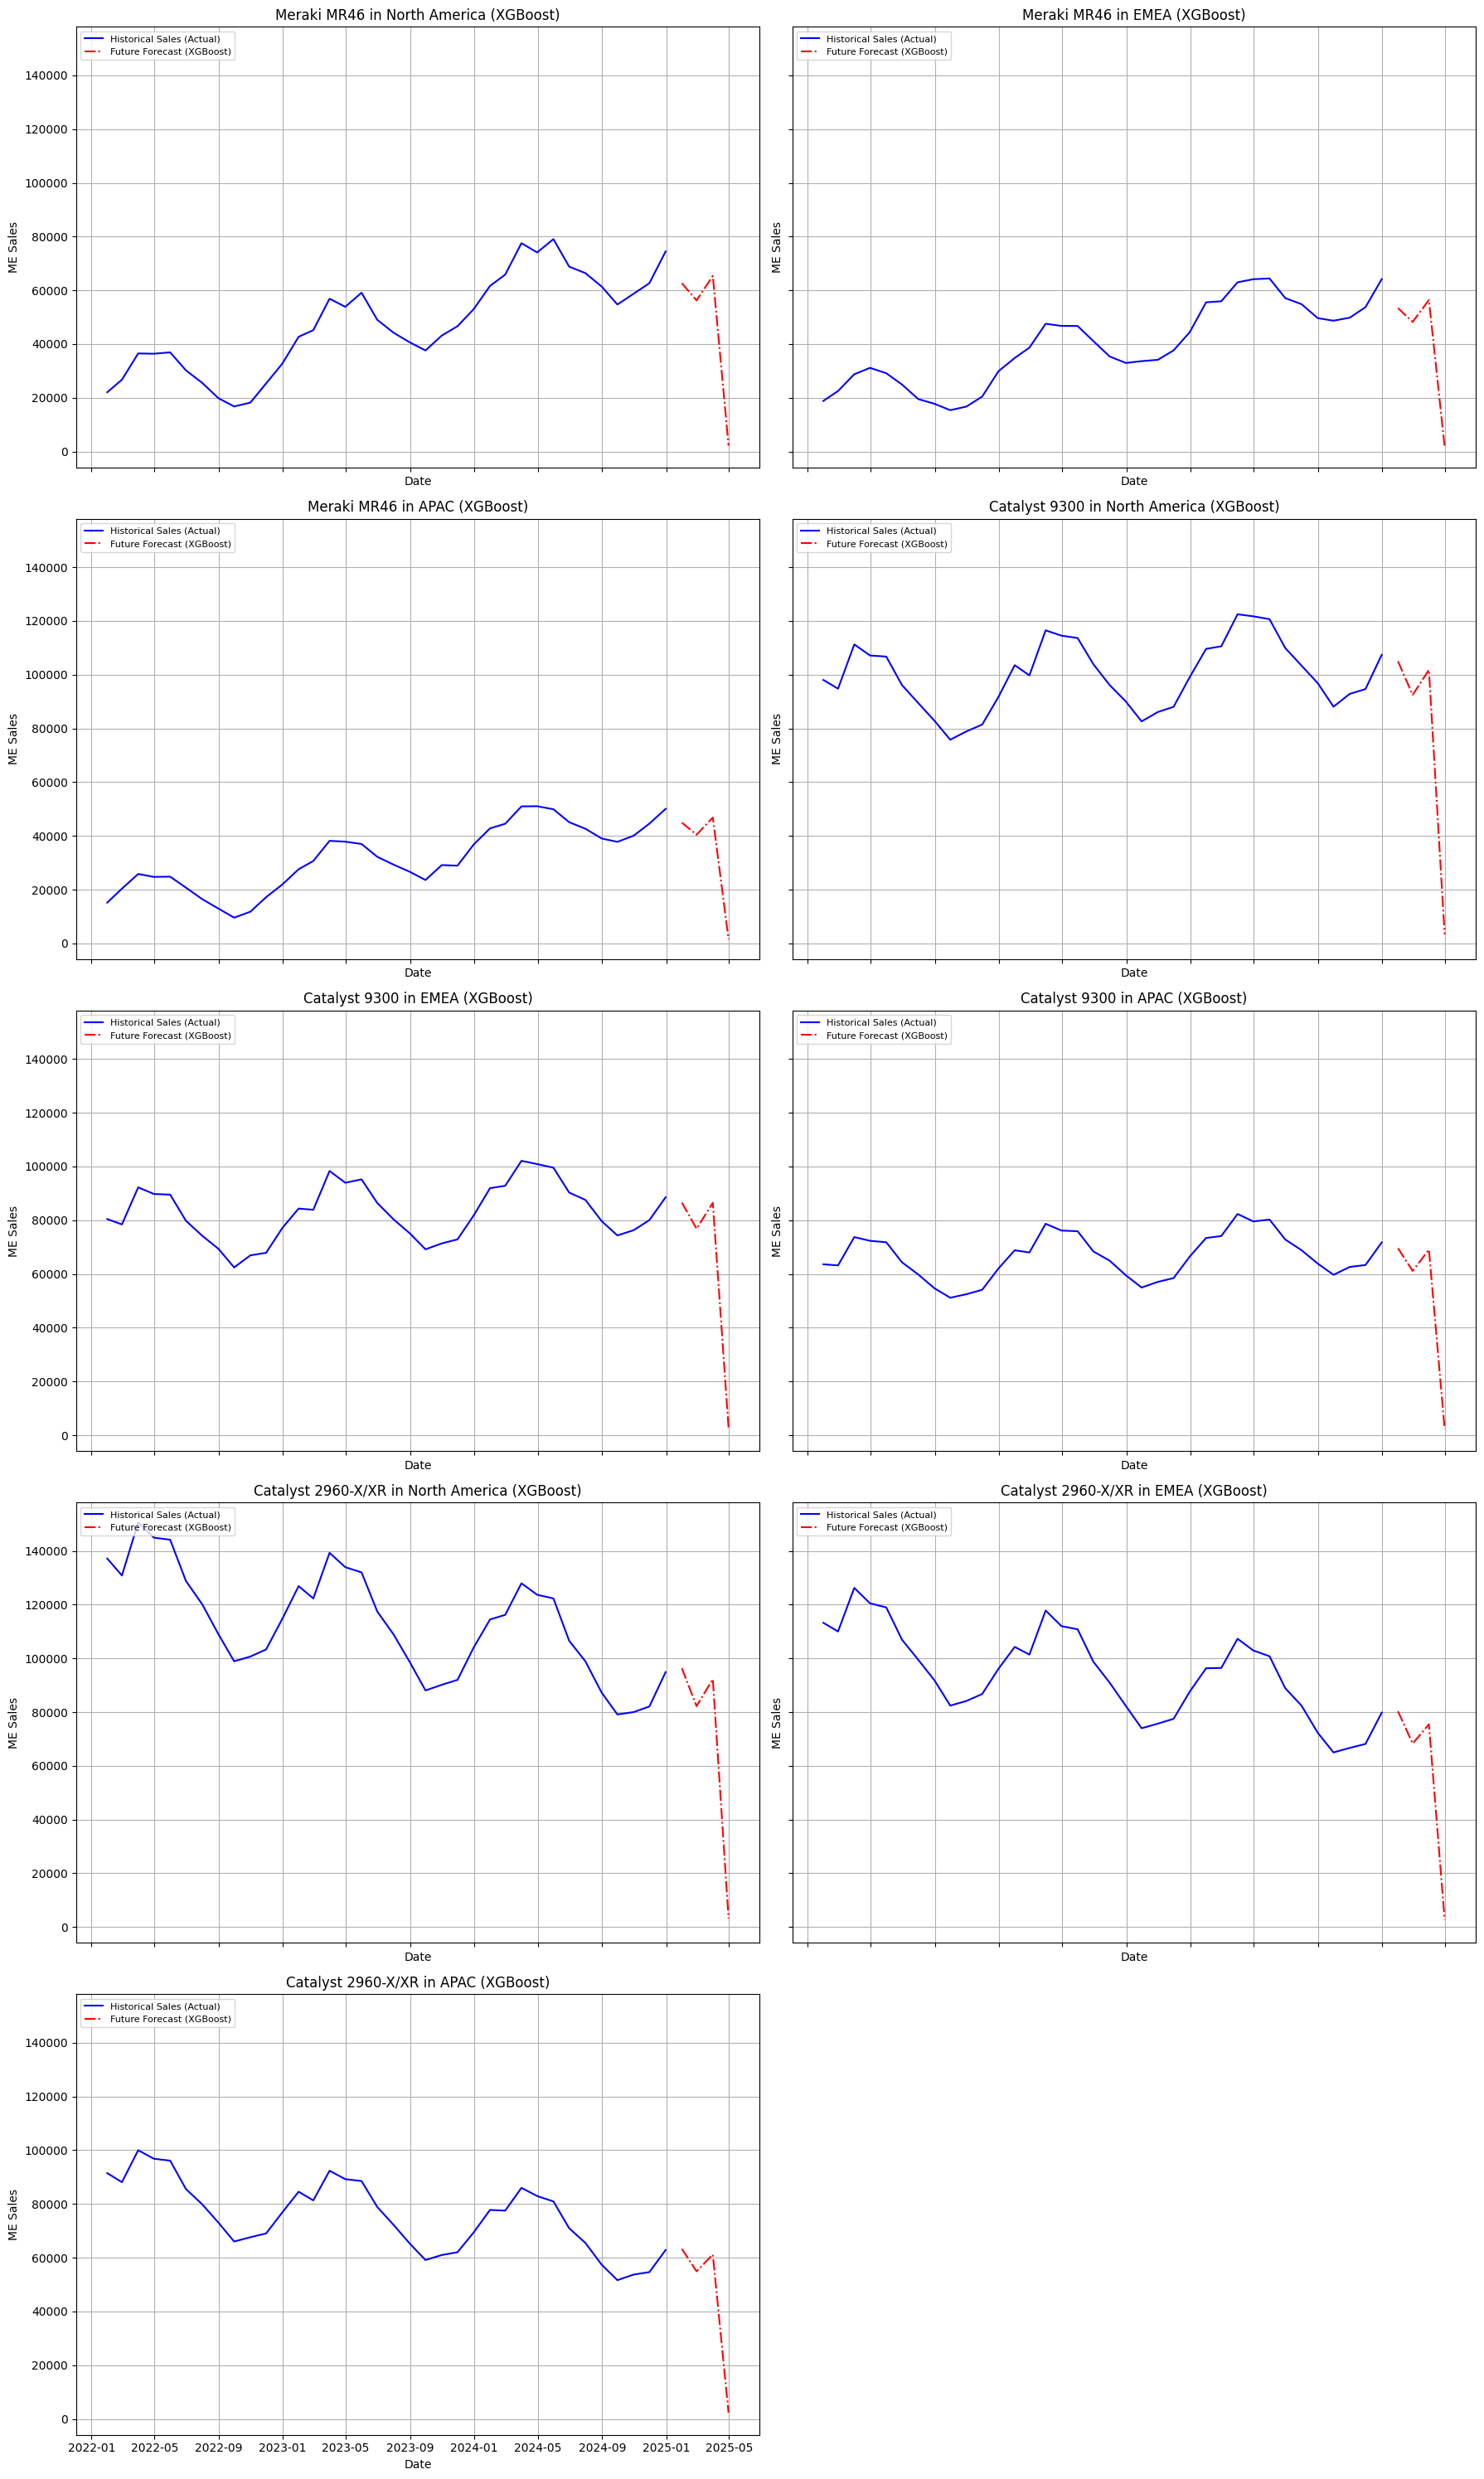


--- Generating Combined North America Sales Forecast (XGBoost) ---


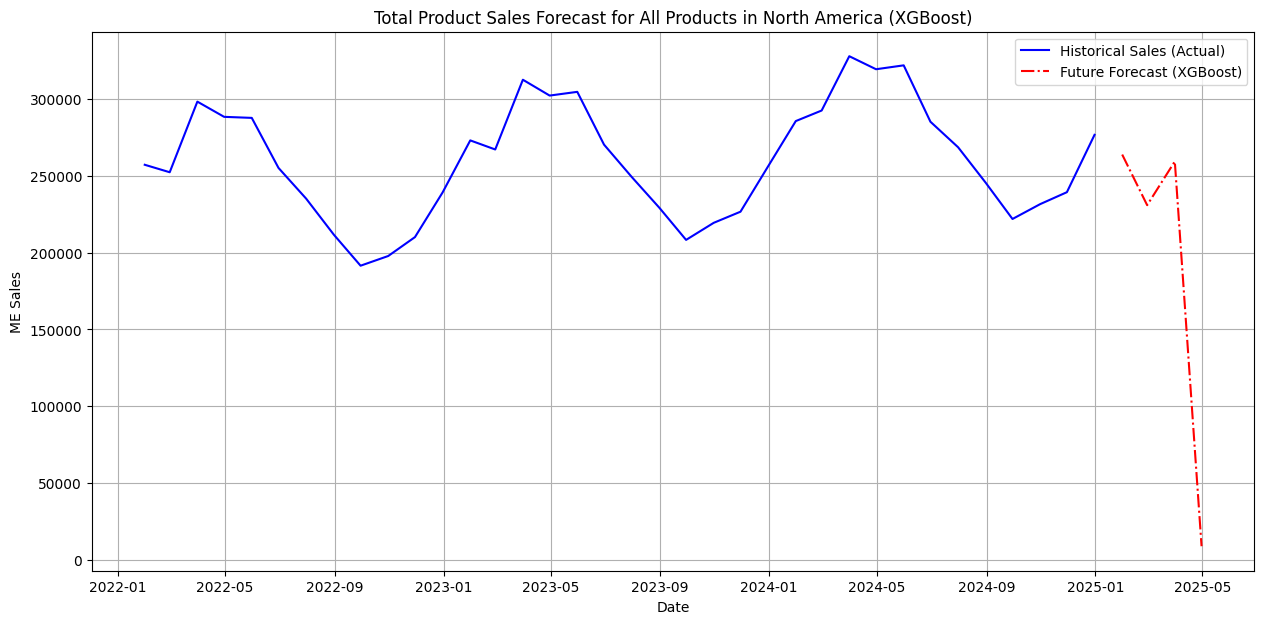

12:01:55 - cmdstanpy - INFO - Chain [1] start processing



Forecast and Visualization complete for XGBoost!

--- Starting Prophet Model Training and Forecasting ---


Training Prophet for: Meraki MR46 in North America


12:01:56 - cmdstanpy - INFO - Chain [1] done processing
12:01:56 - cmdstanpy - INFO - Chain [1] start processing
12:01:56 - cmdstanpy - INFO - Chain [1] done processing


  Prophet Metrics for Meraki MR46 in North America:
    R²: 0.5082
    MAE: 190.00
    RMSE: 238.05

Training Prophet for: Meraki MR46 in EMEA


12:01:56 - cmdstanpy - INFO - Chain [1] start processing
12:01:56 - cmdstanpy - INFO - Chain [1] done processing


  Prophet Metrics for Meraki MR46 in EMEA:
    R²: 0.5444
    MAE: 155.79
    RMSE: 195.44

Training Prophet for: Meraki MR46 in APAC
  Prophet Metrics for Meraki MR46 in APAC:
    R²: 0.5184
    MAE: 128.74
    RMSE: 161.03

Training Prophet for: Catalyst 9300 in North America


... (5 outputs left out)

  Prophet Metrics for Catalyst 2960-X/XR in North America:
    R²: 0.9264
    MAE: 82.69
    RMSE: 103.92

Training Prophet for: Catalyst 2960-X/XR in EMEA


12:01:57 - cmdstanpy - INFO - Chain [1] start processing
12:01:57 - cmdstanpy - INFO - Chain [1] done processing


  Prophet Metrics for Catalyst 2960-X/XR in EMEA:
    R²: 0.8925
    MAE: 86.32
    RMSE: 109.97

Training Prophet for: Catalyst 2960-X/XR in APAC
  Prophet Metrics for Catalyst 2960-X/XR in APAC:
    R²: 0.9283
    MAE: 54.42
    RMSE: 69.24

Prophet Model Training and Forecasting Complete!

--- Summary of Prophet Model Performance on Test Sets ---
     Product_Category         Region      R2       MAE      RMSE
0         Meraki MR46  North America  0.5082  190.0026  238.0505
1         Meraki MR46           EMEA  0.5444  155.7902  195.4446
2         Meraki MR46           APAC  0.5184  128.7401  161.0273
3       Catalyst 9300  North America  0.7877  121.1758  152.8531
4       Catalyst 9300           EMEA  0.7616  105.5444  137.4729
5       Catalyst 9300           APAC  0.7439   87.6547  113.9338
6  Catalyst 2960-X/XR  North America  0.9264   82.6899  103.9183
7  Catalyst 2960-X/XR           EMEA  0.8925   86.3247  109.9743
8  Catalyst 2960-X/XR           APAC  0.9283   54.4224   69.237

KeyError: "None of ['ds'] are in the columns"

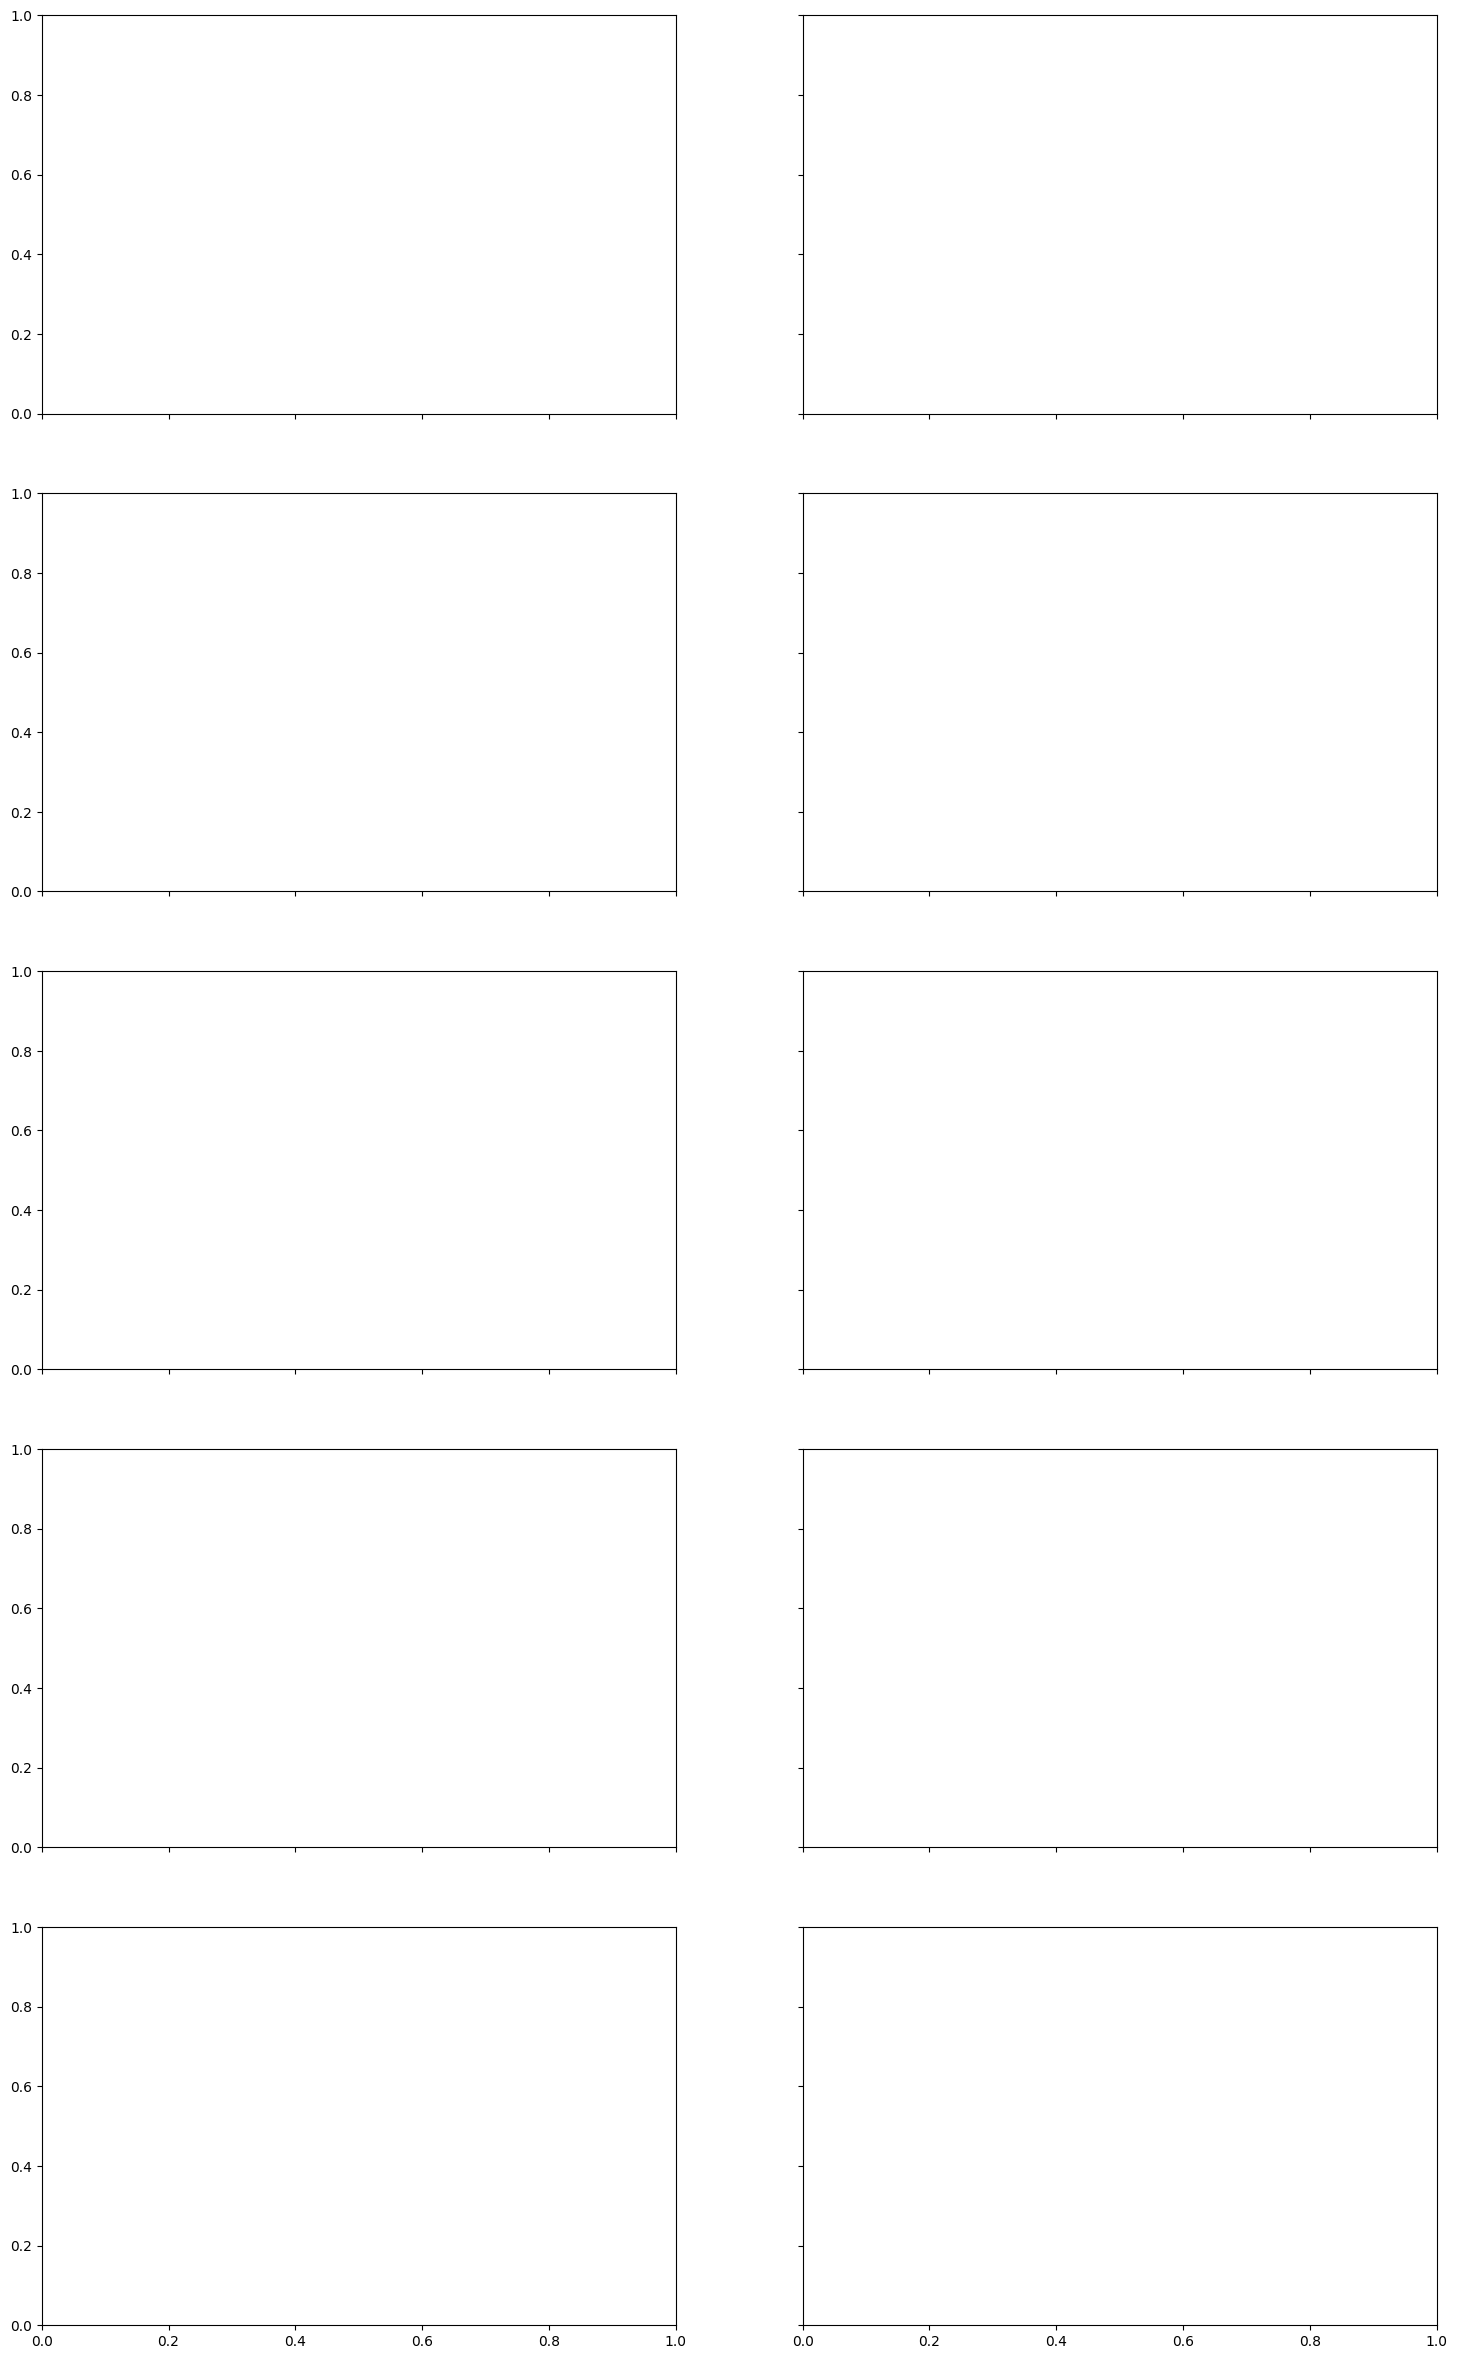

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import KNNImputer
from lightgbm import LGBMRegressor
import xgboost as xgb

# Import Prophet
from prophet import Prophet

# --- 1. Data Loading and Initial Date Conversion ---
# IMPORTANT: Replace this path with the actual path to your new, larger dataset CSV
df_original_full = pd.read_csv('/Users/auperry/Desktop/stretch assignment /larger_dummy_sales_data_lifecycle.csv')
df = df_original_full.copy()

print("--- Data Loading and Initial Inspection ---")
print("Original Data Head:")
print(df.head())
print("\nOriginal Data Info (before processing):")
df.info()
print(f"\nShape after loading CSV: {df.shape}")

# Convert 'Date' column to datetime objects FIRST
df['Date'] = pd.to_datetime(df['Date'])

# --- Store original Date, Product_Category, Region for later use (plotting, future data generation) ---
df_identifiers = df[['Date', 'Product_Category', 'Region', 'Sales']].copy()

# --- 2. Feature Engineering ---
# Create time-based features from the Date column
df['year'] = df['Date'].dt.year
df['month'] = df['Date'].dt.month
df['day'] = df['Date'].dt.day
df['day_of_week'] = df['Date'].dt.dayofweek
df['week_of_year'] = df['Date'].dt.isocalendar().week
df['quarter'] = df['Date'].dt.quarter
df['is_weekend'] = (df['Date'].dt.dayofweek >= 5).astype(int)

# Transform month into sine and cosine (for cyclical patterns)
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

# NEW: Add a continuous time index feature
# This helps capture overall trends that might not be purely seasonal
df['time_idx'] = (df['Date'] - df['Date'].min()).dt.days

# Sort by Date before creating lagged features (CRUCIAL for time series correctness)
df = df.sort_values(by=['Date', 'Product_Category', 'Region']).reset_index(drop=True)

# Lagged Sales Features (powerful for sales forecasting, captures past patterns)
df['Sales_Lag1'] = df['Sales'].shift(1)
df['Sales_Lag7'] = df['Sales'].shift(7)
df['Sales_Lag30'] = df['Sales'].shift(30)
df['Sales_Lag90'] = df['Sales'].shift(90)
df['Sales_Lag180'] = df['Sales'].shift(180)
df['Sales_Lag365'] = df['Sales'].shift(365)

# Rolling Mean Sales (captures trends, shifted by 1 to avoid data leakage)
df['Sales_RollingMean7'] = df['Sales'].rolling(window=7).mean().shift(1)
df['Sales_RollingMean30'] = df['Sales'].rolling(window=30).mean().shift(1)
df['Sales_RollingMean90'] = df['Sales'].rolling(window=90).mean().shift(1)
df['Sales_RollingMean365'] = df['Sales'].rolling(window=365).mean().shift(1)

# Drop the original 'Date' column from the main df for modeling
df = df.drop(columns = ['Date'])

print(f"\nShape after feature engineering (before dropping NaNs): {df.shape}")

# --- 3. Handle NaNs from Lagged Features and Target Variable ---
print(f"\nShape before dropping NaNs from lags/target: {df.shape}")
df = df.dropna(subset=[
    'Sales_Lag1', 'Sales_Lag7', 'Sales_Lag30',
    'Sales_Lag90', 'Sales_Lag180', 'Sales_Lag365',
    'Sales_RollingMean7', 'Sales_RollingMean30',
    'Sales_RollingMean90', 'Sales_RollingMean365',
    'Sales'
])
print(f"Shape after dropping NaNs from lags/target: {df.shape}")

# --- 4. Separate Features (X) and Target (y) ---
df_X = df.drop(columns = ['Sales'])
df_y = df['Sales']

print(f"\nShape of df_X before train_test_split: {df_X.shape}")

# --- 5. Time Series Train/Test Split (CRUCIAL: Split before imputation/encoding) ---
train_size = int(len(df_X) * 0.8)
train_indices = df_X.index[:train_size]
test_indices = df_X.index[train_size:]

X_train = df_X.loc[train_indices]
X_test = df_X.loc[test_indices]
y_train = df_y.loc[train_indices]
y_test = df_y.loc[test_indices]

# Get the dates for train and test sets for plotting (using df_identifiers for original dates)
train_dates = df_identifiers.loc[train_indices, 'Date']
test_dates = df_identifiers.loc[test_indices, 'Date']

print(f"\nShape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")

# --- 6. Handle Missing Values (Imputation) AFTER SPLIT ---
numerical_cols_train = X_train.select_dtypes(include=['int64', 'float64']).columns
imputer = KNNImputer(n_neighbors=5)
if len(numerical_cols_train) > 0:
    X_train[numerical_cols_train] = imputer.fit_transform(X_train[numerical_cols_train])
    X_test[numerical_cols_train] = imputer.transform(X_test[numerical_cols_train])

# --- 7. Categorical Feature Encoding AFTER SPLIT ---
categorical_cols_train = X_train.select_dtypes(include=['object']).columns

label_encoders = {}
one_hot_encoders = {}

for col in categorical_cols_train:
    if X_train[col].nunique() == 2:
        le = LabelEncoder()
        all_categories = pd.concat([X_train[col], X_test[col]]).unique()
        le.fit(all_categories)
        X_train[col] = le.transform(X_train[col])
        X_test[col] = le.transform(X_test[col])
        label_encoders[col] = le
    elif X_train[col].nunique() > 2:
        ohe = OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore')
        ohe.fit(X_train[[col]])

        encoded_train_cols = pd.DataFrame(ohe.transform(X_train[[col]]),
                                          columns=ohe.get_feature_names_out([col]),
                                          index=X_train.index)
        encoded_test_cols = pd.DataFrame(ohe.transform(X_test[[col]]),
                                         columns=ohe.get_feature_names_out([col]),
                                         index=X_test.index)
        X_train = pd.concat([X_train.drop(columns=[col]), encoded_train_cols], axis=1)
        X_test = pd.concat([X_test.drop(columns=[col]), encoded_test_cols], axis=1)
        one_hot_encoders[col] = ohe

missing_cols_in_test = set(X_train.columns) - set(X_test.columns)
for c in missing_cols_in_test:
    X_test[c] = 0
X_test = X_test[X_train.columns]

print("\n--- DataFrame Info after all preprocessing and feature engineering ---")
print("X_train info:")
X_train.info()
print("\nX_test info:")
X_test.info()
print("\nX_train head (after all preprocessing):")
print(X_train.head())

# --- 8. Hyperparameter Tuning with GridSearchCV (Random Forest) ---
model_RF = RandomForestRegressor(random_state = 42)
param_grid_rf = {
    'n_estimators': [100, 200, 500],
    'max_features': ['sqrt', 'log2', 0.8],
    'max_depth': [10, 20, None]
}
print("\n--- Starting GridSearchCV for Random Forest Hyperparameter Tuning ---")
grid_search_rf = GridSearchCV(model_RF, param_grid_rf, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, verbose=0)
grid_search_rf.fit(X_train, y_train)
best_RF_model = grid_search_rf.best_estimator_
y_pred_rf = best_RF_model.predict(X_test)
r2_rf = r2_score(y_test, y_pred_rf)

# --- 9. Hyperparameter Tuning with GridSearchCV (LightGBM) ---
model_LGBM = LGBMRegressor(random_state=42)
param_grid_lgbm = {
    'n_estimators': [100, 200, 500],
    'learning_rate': [0.05, 0.1],
    'num_leaves': [31, 63, 127],
    'max_depth': [-1, 10, 20]
}
print("\n--- Starting GridSearchCV for LightGBM Hyperparameter Tuning ---")
grid_search_lgbm = GridSearchCV(model_LGBM, param_grid_lgbm, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, verbose=0)
grid_search_lgbm.fit(X_train, y_train)
best_LGBM_model = grid_search_lgbm.best_estimator_
y_pred_lgbm = best_LGBM_model.predict(X_test)
r2_lgbm = r2_score(y_test, y_pred_lgbm)

# --- 10. Hyperparameter Tuning with GridSearchCV (XGBoost) ---
model_XGB = xgb.XGBRegressor(objective='reg:squarederror', random_state=42)
param_grid_xgb = {
    'n_estimators': [100, 200, 500],
    'learning_rate': [0.05, 0.1],
    'max_depth': [6, 10, 15],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}
print("\n--- Starting GridSearchCV for XGBoost Hyperparameter Tuning ---")
grid_search_xgb = GridSearchCV(model_XGB, param_grid_xgb, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, verbose=2)
grid_search_xgb.fit(X_train, y_train)
best_XGB_model = grid_search_xgb.best_estimator_
y_pred_xgb = best_XGB_model.predict(X_test)
r2_xgb = r2_score(y_test, y_pred_xgb)

print("\n--- Overall Model Comparison (R² Score) ---")
print(f"Random Forest R²: {r2_rf:.4f}")
print(f"LightGBM R²: {r2_lgbm:.4f}")
print(f"XGBoost R²: {r2_xgb:.4f}")

# --- NEW SECTION: Forecasting and Visualization (XGBoost) ---

print("\n--- Beginning Forecasting and Visualization (XGBoost) ---")

# 1. Prepare data for plotting historical actuals and test predictions
# The df_identifiers is already created at the beginning and contains original Date, Product_Category, Region, Sales.

# Create a DataFrame for test predictions with original identifiers
# This ensures that y_pred_xgb is correctly associated with its corresponding product and region from the test set.
test_predictions_df = df_identifiers.loc[test_indices].copy()
test_predictions_df['Predicted_Sales'] = y_pred_xgb

# 2. Define the forecasting horizon (e.g., next 3 months or 1 quarter)
forecast_start_date = df_identifiers['Date'].max() + pd.Timedelta(days=1)
forecast_end_date = forecast_start_date + pd.Timedelta(days=90) # Forecast for next 90 days

# Create a DataFrame for future dates
future_dates_range = pd.date_range(start=forecast_start_date, end=forecast_end_date, freq='D')

# Get unique product categories and regions from your original full data
unique_product_categories = df_original_full['Product_Category'].unique()
unique_regions = df_original_full['Region'].unique()

# Create all combinations of future dates, products, and regions
future_data_list = []
for date in future_dates_range:
    for product in unique_product_categories:
        for region in unique_regions:
            future_data_list.append({'Date': date, 'Product_Category': product, 'Region': region})

future_df = pd.DataFrame(future_data_list)

# --- 3. Feature Engineering for Future Dates ---
# Apply the same feature engineering steps as on the training data
future_df['year'] = future_df['Date'].dt.year
future_df['month'] = future_df['Date'].dt.month
future_df['day'] = future_df['Date'].dt.day
future_df['day_of_week'] = future_df['Date'].dt.dayofweek
future_df['week_of_year'] = future_df['Date'].dt.isocalendar().week
future_df['quarter'] = future_df['Date'].dt.quarter
future_df['is_weekend'] = (future_df['Date'].dt.dayofweek >= 5).astype(int)
future_df['month_sin'] = np.sin(2 * np.pi * future_df['month'] / 12)
future_df['month_cos'] = np.cos(2 * np.pi * future_df['month'] / 12)

# NEW: Extend time_idx for future dates
# Calculate time_idx relative to the original df_original_full['Date'].min()
original_min_date = df_identifiers['Date'].min() # CORRECTED LINE
future_df['time_idx'] = (future_df['Date'] - original_min_date).dt.days

# For 'Price', 'Marketing_Spend', 'Promotion' in future_df:
# Using mean for now, as no projected values are available.
# This means these features won't drive new growth beyond historical averages.
for col in ['Price', 'Marketing_Spend', 'Promotion']:
    if col in X_train.columns:
        future_df[col] = X_train[col].mean()
    else:
        future_df[col] = 0

# --- Prepare full_data_for_lags for iterative forecasting ---
# This DataFrame will hold historical actuals and then be updated with predictions
# for calculating future lags.
full_data_for_lags = df_identifiers.copy() # Use df_identifiers which has all original data
# Add a placeholder 'Sales' column to future_df for concatenation
future_df_for_lags_concat = future_df.copy()
future_df_for_lags_concat['Sales'] = np.nan
full_data_for_lags = pd.concat([full_data_for_lags, future_df_for_lags_concat], ignore_index=True)
full_data_for_lags['Date'] = pd.to_datetime(full_data_for_lags['Date'])
full_data_for_lags = full_data_for_lags.sort_values(by=['Date', 'Product_Category', 'Region']).reset_index(drop=True)

# Determine the index where future forecasting begins
# This is the first row in full_data_for_lags that corresponds to a future date
# and was not part of the original historical data.
start_forecast_idx = full_data_for_lags['Sales'].isnull().idxmax()
if pd.isna(full_data_for_lags.loc[start_forecast_idx, 'Sales']):
    print(f"\nCalculated start_forecast_idx: {start_forecast_idx}")
    print(f"Date at start_forecast_idx: {full_data_for_lags.loc[start_forecast_idx, 'Date']}")
else:
    start_forecast_idx = len(df_identifiers)
    print(f"\nAdjusted start_forecast_idx to len(df_identifiers): {start_forecast_idx}")


print(f"Total rows in full_data_for_lags: {len(full_data_for_lags)}")
if start_forecast_idx < len(full_data_for_lags):
    print(f"Expected forecast_start_date: {forecast_start_date}")
else:
    print("Warning: No future data to forecast or forecast period is too short.")

# Iterative Forecasting Loop
forecasted_sales_list = []

for i in range(start_forecast_idx, len(full_data_for_lags)):
    current_row_data = full_data_for_lags.loc[i].copy()
    current_date = current_row_data['Date']
    current_product = current_row_data['Product_Category']
    current_region = current_row_data['Region']

    # Initialize temp_X_row with features from future_df that were already engineered
    temp_X_row_dict = {
        'year': current_date.year,
        'month': current_date.month,
        'day': current_date.day,
        'day_of_week': current_date.dayofweek,
        'week_of_year': current_date.isocalendar().week,
        'quarter': current_date.quarter,
        'is_weekend': int(current_date.dayofweek >= 5),
        'month_sin': np.sin(2 * np.pi * current_date.month / 12),
        'month_cos': np.cos(2 * np.pi * current_date.month / 12),
        'time_idx': (current_date - original_min_date).days # Ensure time_idx is correct for current_date
    }
    # Add 'Price', 'Marketing_Spend', 'Promotion' if they are in X_train
    for col in ['Price', 'Marketing_Spend', 'Promotion']:
        if col in X_train.columns:
            # Use the value from future_df (which was set to mean or projected)
            temp_X_row_dict[col] = future_df.loc[
                (future_df['Date'] == current_date) &
                (future_df['Product_Category'] == current_product) &
                (future_df['Region'] == current_region),
                col
            ].iloc[0]
        else:
            temp_X_row_dict[col] = 0

    temp_X_row = pd.DataFrame([temp_X_row_dict])

    product_region_history = full_data_for_lags[
        (full_data_for_lags['Product_Category'] == current_product) &
        (full_data_for_lags['Region'] == current_region) &
        (full_data_for_lags['Date'] < current_date)
    ].sort_values(by='Date')

    # Fill lagged features for the current row
    temp_X_row['Sales_Lag1'] = product_region_history['Sales'].iloc[-1] if len(product_region_history) >= 1 else X_train['Sales_Lag1'].mean()
    temp_X_row['Sales_Lag7'] = product_region_history['Sales'].iloc[-7] if len(product_region_history) >= 7 else X_train['Sales_Lag7'].mean()
    temp_X_row['Sales_Lag30'] = product_region_history['Sales'].iloc[-30] if len(product_region_history) >= 30 else X_train['Sales_Lag30'].mean()
    temp_X_row['Sales_Lag90'] = product_region_history['Sales'].iloc[-90] if len(product_region_history) >= 90 else X_train['Sales_Lag90'].mean()
    temp_X_row['Sales_Lag180'] = product_region_history['Sales'].iloc[-180] if len(product_region_history) >= 180 else X_train['Sales_Lag180'].mean()
    temp_X_row['Sales_Lag365'] = product_region_history['Sales'].iloc[-365] if len(product_region_history) >= 365 else X_train['Sales_Lag365'].mean()

    # Calculate rolling means
    temp_X_row['Sales_RollingMean7'] = product_region_history['Sales'].tail(7).mean() if len(product_region_history) >= 7 else X_train['Sales_RollingMean7'].mean()
    temp_X_row['Sales_RollingMean30'] = product_region_history['Sales'].tail(30).mean() if len(product_region_history) >= 30 else X_train['Sales_RollingMean30'].mean()
    temp_X_row['Sales_RollingMean90'] = product_region_history['Sales'].tail(90).mean() if len(product_region_history) >= 90 else X_train['Sales_RollingMean90'].mean()
    temp_X_row['Sales_RollingMean365'] = product_region_history['Sales'].tail(365).mean() if len(product_region_history) >= 365 else X_train['Sales_RollingMean365'].mean()

    # Re-apply categorical encoding for the current row
    temp_cat_df = pd.DataFrame([{'Product_Category': current_product, 'Region': current_region}])

    for cat_col_name in ['Product_Category', 'Region']:
        if cat_col_name in label_encoders:
            encoder = label_encoders[cat_col_name]
            temp_cat_df[cat_col_name] = encoder.transform(temp_cat_df[cat_col_name])
        elif cat_col_name in one_hot_encoders:
            encoder = one_hot_encoders[cat_col_name]
            try:
                encoded_cols = pd.DataFrame(encoder.transform(temp_cat_df[[cat_col_name]]),
                                            columns=encoder.get_feature_names_out([cat_col_name]),
                                            index=temp_cat_df.index)
            except ValueError:
                print(f"Warning: Category '{temp_cat_df[cat_col_name].iloc[0]}' not seen during encoding for {cat_col_name}. Setting to zeros.")
                encoded_cols = pd.DataFrame(0, index=temp_cat_df.index, columns=encoder.get_feature_names_out([cat_col_name]))

            temp_cat_df = pd.concat([temp_cat_df.drop(columns=[cat_col_name]), encoded_cols], axis=1)

    # Combine numerical and categorical features into a single row for prediction
    final_X_row = pd.DataFrame(columns=X_train.columns)

    for col in temp_X_row.columns:
        if col in final_X_row.columns:
            final_X_row[col] = temp_X_row[col]

    for col in temp_cat_df.columns:
        if col in final_X_row.columns:
            final_X_row[col] = temp_cat_df[col]
        else:
            final_X_row[col] = 0.0

    for col in X_train.columns:
        if col not in final_X_row.columns:
            final_X_row[col] = 0.0
    final_X_row = final_X_row[X_train.columns]

    if len(numerical_cols_train) > 0:
        cols_to_impute = [col for col in numerical_cols_train if col in final_X_row.columns]
        if cols_to_impute:
            final_X_row[cols_to_impute] = imputer.transform(final_X_row[cols_to_impute].values.reshape(1, -1))


    predicted_sales = best_XGB_model.predict(final_X_row)[0]

    forecasted_sales_list.append({
        'Date': current_date,
        'Product_Category': current_product,
        'Region': current_region,
        'Sales': predicted_sales
    })

    full_data_for_lags.loc[i, 'Sales'] = predicted_sales

forecast_df = pd.DataFrame(forecasted_sales_list)

# --- 4. Enhanced Visualization for All Products/Regions (XGBoost) ---
print("\n--- Beginning Visualization for All Products/Regions (XGBoost) ---")

# Define the aggregation frequency ('W' for weekly, 'M' for monthly)
resample_freq = 'ME' # Changed from 'M' to 'ME' for Month End
y_label_text = f'{resample_freq} Sales' # Update y-axis label based on frequency

# Get all unique product-region combinations from the original full data
all_combinations = df_original_full[['Product_Category', 'Region']].drop_duplicates().values

# Determine subplot grid size (e.g., 2 columns, adjust as needed)
num_combinations = len(all_combinations)
ncols = 2 # You can adjust this number based on how many plots you want per row
nrows = (num_combinations + ncols - 1) // ncols # Ceiling division

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(18, 6 * nrows), sharex=True, sharey=True)
axes = axes.flatten() # Flatten the array of axes for easy iteration

for i, (product_to_plot, region_to_plot) in enumerate(all_combinations):
    ax = axes[i]

    # Filter historical data for the current product/region
    historical_plot_df_filtered = df_identifiers[
        (df_identifiers['Product_Category'] == product_to_plot) &
        (df_identifiers['Region'] == region_to_plot)
    ].copy()

    # Filter future forecast for the current product/region
    forecast_plot_df_filtered = forecast_df[
        (forecast_df['Product_Category'] == product_to_plot) &
        (forecast_df['Region'] == region_to_plot)
    ].copy()

    # --- Perform Aggregation ---
    historical_plot_df_agg = historical_plot_df_filtered.set_index('Date').resample(resample_freq)['Sales'].sum().reset_index()
    forecast_plot_df_agg = forecast_plot_df_filtered.set_index('Date').resample(resample_freq)['Sales'].sum().reset_index()

    # Plotting aggregated data
    ax.plot(historical_plot_df_agg['Date'], historical_plot_df_agg['Sales'], label='Historical Sales (Actual)', color='blue')
    ax.plot(forecast_plot_df_agg['Date'], forecast_plot_df_agg['Sales'], label='Future Forecast (XGBoost)', color='red', linestyle='-.')

    ax.set_title(f'{product_to_plot} in {region_to_plot} (XGBoost)') # Added model name
    ax.set_xlabel('Date')
    ax.set_ylabel(y_label_text) # Updated y-axis label
    ax.legend(loc='upper left', prop={'size': 8}) # Adjust legend size for subplots
    ax.grid(True)

# Hide any unused subplots if the number of combinations doesn't perfectly fill the grid
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout() # Adjusts subplot params for a tight layout
plt.show()


# --- NEW SECTION: Combined North America Sales Forecast (XGBoost) ---
print("\n--- Generating Combined North America Sales Forecast (XGBoost) ---")

region_to_combine = 'North America'

# 1. Filter data for North America
historical_na_df = df_identifiers[df_identifiers['Region'] == region_to_combine].copy()
forecast_na_df = forecast_df[forecast_df['Region'] == region_to_combine].copy()

# 2. Sum sales across all products for each date
historical_na_total = historical_na_df.groupby('Date')['Sales'].sum().reset_index()
forecast_na_total = forecast_na_df.groupby('Date')['Sales'].sum().reset_index()

# 3. Apply aggregation (e.g., monthly)
historical_na_agg = historical_na_total.set_index('Date').resample(resample_freq)['Sales'].sum().reset_index()
forecast_na_agg = forecast_na_total.set_index('Date').resample(resample_freq)['Sales'].sum().reset_index()

# 4. Plot the combined North America data
plt.figure(figsize=(15, 7))
plt.plot(historical_na_agg['Date'], historical_na_agg['Sales'], label='Historical Sales (Actual)', color='blue')
plt.plot(forecast_na_agg['Date'], forecast_na_agg['Sales'], label='Future Forecast (XGBoost)', color='red', linestyle='-.')

plt.title(f'Total Product Sales Forecast for All Products in {region_to_combine} (XGBoost)') # Added model name
plt.xlabel('Date')
plt.ylabel(y_label_text)
plt.legend()
plt.grid(True)
plt.show()

print("\nForecast and Visualization complete for XGBoost!")


# ==============================================================================
# --- NEW MAJOR SECTION: Prophet Model Training and Forecasting ---
# ==============================================================================
print("\n" + "="*80)
print("--- Starting Prophet Model Training and Forecasting ---")
print("="*80 + "\n")

# Store Prophet results
prophet_forecasts = {}
prophet_metrics = [] # List to store metrics for each combination

# Get unique product categories and regions from your original full data
unique_product_categories = df_original_full['Product_Category'].unique()
unique_regions = df_original_full['Region'].unique()

for product_cat in unique_product_categories:
    for region_name in unique_regions:
        print(f"\nTraining Prophet for: {product_cat} in {region_name}")

        # Prepare data for Prophet: needs 'ds' and 'y' columns
        # Use df_identifiers for raw historical data
        series_data = df_identifiers[
            (df_identifiers['Product_Category'] == product_cat) &
            (df_identifiers['Region'] == region_name)
        ].copy()

        # Rename columns for Prophet
        series_data = series_data.rename(columns={'Date': 'ds', 'Sales': 'y'})

        # Ensure 'ds' is datetime and 'y' is numeric
        series_data['ds'] = pd.to_datetime(series_data['ds'])
        series_data['y'] = pd.to_numeric(series_data['y'])

        # Split data for Prophet (using the same split point as XGBoost for consistency)
        prophet_train_df = series_data[series_data['ds'].isin(train_dates)].copy()
        prophet_test_df = series_data[series_data['ds'].isin(test_dates)].copy()

        if prophet_train_df.empty:
            print(f"  Skipping {product_cat} in {region_name}: No training data for Prophet.")
            continue
        # No need to skip if test_df is empty, just metrics won't be calculated.

        # Initialize Prophet model
        m = Prophet(
            daily_seasonality=False,
            weekly_seasonality=True,
            yearly_seasonality=True,
            seasonality_mode='additive'
        )
        m.fit(prophet_train_df)

        # --- More Robust future_prophet generation for Prophet ---
        # Get all dates that Prophet needs to predict for (training, test, and future forecast)
        all_prediction_dates_series = pd.concat([
            prophet_train_df['ds'],
            prophet_test_df['ds'],
            pd.Series(future_dates_range) # Convert date_range to Series
        ]).drop_duplicates().sort_values().reset_index(drop=True)

        if all_prediction_dates_series.empty:
            print(f"  Warning: No dates to predict for {product_cat} in {region_name}. Skipping prediction.")
            prophet_forecasts[(product_cat, region_name)] = {
                'historical_actuals': series_data,
                'prophet_history_pred': pd.DataFrame(columns=['ds', 'Predicted_Sales_Prophet']),
                'prophet_test_pred': pd.DataFrame(columns=['ds', 'Predicted_Sales_Prophet']),
                'prophet_future_pred': pd.DataFrame(columns=['ds', 'Sales_Prophet'])
            }
            continue

        # Calculate periods from the *start* of the training data to the maximum date in all_prediction_dates_series
        # This is the standard way Prophet expects make_future_dataframe to be used.
        periods_from_train_start = (all_prediction_dates_series.max() - prophet_train_df['ds'].min()).days + 1

        future_prophet = m.make_future_dataframe(periods=periods_from_train_start, freq='D', include_history=True)
        # Filter future_prophet to only contain dates relevant to our prediction ranges
        future_prophet = future_prophet[future_prophet['ds'].isin(all_prediction_dates_series)]
        
        if future_prophet.empty:
            print(f"  Warning: future_prophet is empty after filtering for {product_cat} in {region_name}. Skipping prediction.")
            prophet_forecasts[(product_cat, region_name)] = {
                'historical_actuals': series_data,
                'prophet_history_pred': pd.DataFrame(columns=['ds', 'Predicted_Sales_Prophet']),
                'prophet_test_pred': pd.DataFrame(columns=['ds', 'Predicted_Sales_Prophet']),
                'prophet_future_pred': pd.DataFrame(columns=['ds', 'Sales_Prophet'])
            }
            continue
        
        # Make predictions
        forecast_prophet = m.predict(future_prophet)
        
        # Now, extract predictions using the original date ranges
        # Historical (fitted values) - these are within the training period
        prophet_history_pred = forecast_prophet[['ds', 'yhat']].set_index('ds').loc[prophet_train_df['ds']].reset_index()
        prophet_history_pred = prophet_history_pred.rename(columns={'yhat': 'Predicted_Sales_Prophet'})

        # Test set predictions - these are within the test period
        # Use .reindex for robustness if some test_dates are not in forecast_prophet (shouldn't happen with new logic)
        prophet_test_pred_for_metrics = forecast_prophet[['ds', 'yhat']].set_index('ds').reindex(prophet_test_df['ds']).reset_index()
        prophet_test_pred_for_metrics = prophet_test_pred_for_metrics.rename(columns={'yhat': 'Predicted_Sales_Prophet'})
        prophet_test_pred_for_metrics = prophet_test_pred_for_metrics.dropna(subset=['Predicted_Sales_Prophet']) # Drop NaNs if reindex created them

        # Future forecast - these are within the future_dates_range
        prophet_future_pred = forecast_prophet[['ds', 'yhat']].set_index('ds').reindex(pd.Series(future_dates_range)).reset_index()
        prophet_future_pred = prophet_future_pred.rename(columns={'yhat': 'Sales_Prophet'})
        prophet_future_pred = prophet_future_pred.dropna(subset=['Sales_Prophet']) # Drop NaNs if reindex created them

        # --- Calculate Metrics for Prophet Test Set ---
        if not prophet_test_df.empty and not prophet_test_pred_for_metrics.empty:
            # Align actuals and predictions by date
            # Ensure both are sorted and aligned before extracting values
            aligned_df = pd.merge(prophet_test_df, prophet_test_pred_for_metrics, on='ds', how='inner')
            
            if not aligned_df.empty:
                y_true_prophet = aligned_df['y'].values
                y_pred_prophet = aligned_df['Predicted_Sales_Prophet'].values

                r2_prophet = r2_score(y_true_prophet, y_pred_prophet)
                mae_prophet = mean_absolute_error(y_true_prophet, y_pred_prophet)
                rmse_prophet = np.sqrt(mean_squared_error(y_true_prophet, y_pred_prophet))

                print(f"  Prophet Metrics for {product_cat} in {region_name}:")
                print(f"    R²: {r2_prophet:.4f}")
                print(f"    MAE: {mae_prophet:.2f}")
                print(f"    RMSE: {rmse_prophet:.2f}")

                prophet_metrics.append({
                    'Product_Category': product_cat,
                    'Region': region_name,
                    'R2': r2_prophet,
                    'MAE': mae_prophet,
                    'RMSE': rmse_prophet
                })
            else:
                print(f"  No overlapping test data for metrics calculation for {product_cat} in {region_name}.")
        else:
            print(f"  No sufficient test data for metrics calculation for {product_cat} in {region_name}.")

        # Store results
        prophet_forecasts[(product_cat, region_name)] = {
            'historical_actuals': series_data, # Original actuals (ds, y)
            'prophet_history_pred': prophet_history_pred, # Prophet's fitted values on training data
            'prophet_test_pred': prophet_test_pred_for_metrics, # Prophet's predictions on test data
            'prophet_future_pred': prophet_future_pred
        }

print("\nProphet Model Training and Forecasting Complete!")

# --- Print Summary of Prophet Metrics ---
if prophet_metrics:
    prophet_metrics_df = pd.DataFrame(prophet_metrics)
    print("\n--- Summary of Prophet Model Performance on Test Sets ---")
    print(prophet_metrics_df.round(4))
    print(f"\nAverage R² (Prophet): {prophet_metrics_df['R2'].mean():.4f}")
    print(f"Average MAE (Prophet): {prophet_metrics_df['MAE'].mean():.2f}")
    print(f"Average RMSE (Prophet): {prophet_metrics_df['RMSE'].mean():.2f}")
else:
    print("\nNo Prophet metrics were calculated (insufficient test data for all combinations).")


# ==============================================================================
# --- NEW SECTION: Visualization for Prophet Model ---
# ==============================================================================
print("\n" + "="*80)
print("--- Beginning Visualization for All Products/Regions (Prophet) ---")
print("="*80 + "\n")

# Determine subplot grid size (same as XGBoost for consistency)
num_combinations = len(all_combinations)
ncols = 2
nrows = (num_combinations + ncols - 1) // ncols

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(18, 6 * nrows), sharex=True, sharey=True)
axes = axes.flatten()

for i, (product_to_plot, region_to_plot) in enumerate(all_combinations):
    ax = axes[i]

    if (product_to_plot, region_to_plot) not in prophet_forecasts:
        ax.set_title(f'{product_to_plot} in {region_to_plot} (Prophet - No Data)')
        ax.text(0.5, 0.5, 'No data for this combination', horizontalalignment='center', verticalalignment='center', transform=ax.transAxes)
        ax.grid(True)
        continue

    data = prophet_forecasts[(product_to_plot, region_to_plot)]

    historical_actuals = data['historical_actuals']
    prophet_test_pred = data['prophet_test_pred'] # Use this for plotting the test set prediction
    prophet_future_pred = data['prophet_future_pred']

    # Aggregate for plotting (using the same resample_freq)
    # Check if DataFrames are empty before resampling to avoid errors on empty data
    historical_actuals_agg = historical_actuals.set_index('ds').resample(resample_freq)['y'].sum().reset_index() if not historical_actuals.empty else pd.DataFrame(columns=['ds', 'y'])
    prophet_test_pred_agg = prophet_test_pred.set_index('ds').resample(resample_freq)['Predicted_Sales_Prophet'].sum().reset_index() if not prophet_test_pred.empty else pd.DataFrame(columns=['ds', 'Predicted_Sales_Prophet'])
    prophet_future_pred_agg = prophet_future_pred.set_index('ds').resample(resample_freq)['Sales_Prophet'].sum().reset_index() if not prophet_future_pred.empty else pd.DataFrame(columns=['ds', 'Sales_Prophet'])

    # Plotting
    if not historical_actuals_agg.empty:
        ax.plot(historical_actuals_agg['ds'], historical_actuals_agg['y'], label='Historical Sales (Actual)', color='blue')
    if not prophet_test_pred_agg.empty:
        ax.plot(prophet_test_pred_agg['ds'], prophet_test_pred_agg['Predicted_Sales_Prophet'], label='Test Set Predictions (Prophet)', color='green', linestyle='--', alpha=0.7)
    if not prophet_future_pred_agg.empty:
        ax.plot(prophet_future_pred_agg['ds'], prophet_future_pred_agg['Sales_Prophet'], label='Future Forecast (Prophet)', color='red', linestyle='-.')

    ax.set_title(f'{product_to_plot} in {region_to_plot} (Prophet)')
    ax.set_xlabel('Date')
    ax.set_ylabel(y_label_text)
    ax.legend(loc='upper left', prop={'size': 8})
    ax.grid(True)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

print("\nProphet Visualization for All Products/Regions Complete!")

# ==============================================================================
# --- NEW SECTION: Combined North America Sales Forecast (Prophet) ---
# ==============================================================================
print("\n" + "="*80)
print("--- Generating Combined North America Sales Forecast (Prophet) ---")
print("="*80 + "\n")

region_to_combine = 'North America'

# Prepare data for Prophet combined NA forecast
combined_na_prophet_data = []
for (product_cat, region_name), data in prophet_forecasts.items():
    if region_name == region_to_combine:
        # Get historical actuals for this product/region
        hist_actuals = data['historical_actuals'][['ds', 'y']].copy()
        hist_actuals['type'] = 'actual'
        hist_actuals['product'] = product_cat

        # Get Prophet's combined test and future predictions for this product/region
        # Combine test and future predictions into one series for easier aggregation
        # Ensure 'ds' column is present before concatenating
        test_pred_df = data['prophet_test_pred'].copy()
        future_pred_df = data['prophet_future_pred'].copy()

        # Handle empty dataframes before renaming/concatenating
        if not test_pred_df.empty:
            test_pred_df = test_pred_df.rename(columns={'Predicted_Sales_Prophet': 'Sales'})
        if not future_pred_df.empty:
            future_pred_df = future_pred_df.rename(columns={'Sales_Prophet': 'Sales'})

        all_prophet_preds = pd.concat([test_pred_df, future_pred_df])
        
        if not all_prophet_preds.empty:
            all_prophet_preds['type'] = 'predicted'
            all_prophet_preds['product'] = product_cat
            all_prophet_preds = all_prophet_preds.rename(columns={'ds': 'Date'})

            # Append to combined list
            combined_na_prophet_data.append(hist_actuals.rename(columns={'ds': 'Date', 'y': 'Sales'}))
            combined_na_prophet_data.append(all_prophet_preds)

if combined_na_prophet_data:
    combined_na_prophet_df = pd.concat(combined_na_prophet_data)

    # Sum sales across all products for each date and type (actual/predicted)
    combined_na_prophet_total = combined_na_prophet_df.groupby(['Date', 'type'])['Sales'].sum().unstack(fill_value=0).reset_index()

    # Apply aggregation (e.g., monthly)
    historical_na_prophet_agg = combined_na_prophet_total.set_index('Date').resample(resample_freq)['actual'].sum().reset_index()
    predicted_na_prophet_agg = combined_na_prophet_total.set_index('Date').resample(resample_freq)['predicted'].sum().reset_index()

    # Plot the combined North America data
    plt.figure(figsize=(15, 7))
    if not historical_na_prophet_agg.empty:
        plt.plot(historical_na_prophet_agg['Date'], historical_na_prophet_agg['actual'], label='Historical Sales (Actual)', color='blue')
    if not predicted_na_prophet_agg.empty:
        plt.plot(predicted_na_prophet_agg['Date'], predicted_na_prophet_agg['predicted'], label='Forecast (Prophet)', color='red', linestyle='-.')

    plt.title(f'Total Product Sales Forecast for All Products in {region_to_combine} (Prophet)')
    plt.xlabel('Date')
    plt.ylabel(y_label_text)
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print(f"No data found for combined Prophet forecast in {region_to_combine}.")

print("\nProphet Combined North America Forecast Complete!")